# Comparaison des modèles de vieillissement simple et complexe

## PEMFC — PEMWE — conséquences sur les impacts environnementaux

Ce notebook étudie l'**incertitude structurelle du modèle** : les mêmes données expérimentales, les mêmes services, les mêmes facteurs ACV et les mêmes définitions de fin de vie sont conservés, mais deux représentations du vieillissement sont comparées. Toutes les constantes proviennent de la littérature.

### Modèle simple PEMFC

$$V_{cell}(I,t)=V_{cell}(I,0)-k_{deg,FC}t,$$

avec $k_{deg,FC}$ tel que la perte de 10 % à 300 A soit atteinte en 4 100 h, meilleure durabilité observée sur route (DOE, 2016), soit environ 17,9 µV/h par cellule.

### Modèle simple PEMWE

$$V_{cell}(j,t)=V_{cell}(j,0)+\mu_{WE}t,$$

avec $\mu_{WE}=4{,}8$ µV/h par cellule, taux de dégradation de l'état de l'art 2022 (DOE), appliqué directement au profil.

### Modèles complexes

- PEMFC : perte d'ECSA, résistance apparente et crossover (Colombo et al., 2023), fin de vie à 10 % de perte de tension (DOE) ; le crossover augmente la consommation ;
- PEMWE : perte d'activité anodique et croissance des résistances mesurées par Padgett et al. (2025) et Rakousky et al. (2016) ; rendement faradique lié à l'amincissement de membrane (Chandesris et al., 2015).

La comparaison mesure l'effet du niveau de complexité choisi sur la durée de vie, les consommations et l'ACV.

> **Statut dans l'étude.** L'étude retient trois cas de vieillissement : **optimiste** et **central** = modèle linéaire (objectifs et statut du DOE) ; **pessimiste** = modèle par mécanismes. Les résultats de l'étude sont calculés dans `AB_vieillissement_trois_cas`.
>
> Ce notebook calcule le modèle par mécanismes. Seul son scénario « Pessimiste » correspond à un cas de l'étude. Pour la pile, les scénarios « Optimiste » (cellule B) et « Moyen » restent des analyses de l'annexe S8. Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » ne sont plus utilisés : ils mêlaient l'activité de l'anode (plateau 10,4/93, temps 1,0 kh) et sa capacité (plateau 0,49, temps 1,1 kh), qui sont deux grandeurs différentes.

## 1. Initialisation et données embarquées

Le notebook contient directement les profils expérimentaux utilisés. Il ne dépend donc pas d'un chemin Windows ni de la présence d'un fichier Excel externe.

## 0. Fichiers d'entrée

Cette cellule prépare les fichiers de mesures dont le notebook a besoin, dans le dossier du notebook. Il n'y a rien à faire : exécutez-la simplement.

- Si un fichier est déjà là, il est gardé.
- Sinon, il est pris dans le dossier `data/` du dépôt (si le notebook est dans `h2-ageing-lca/notebooks/`), ou téléchargé depuis le dépôt GitHub public (connexion internet nécessaire).

In [ ]:
BESOINS = ['pemwe_parametres.json']

import json, shutil, urllib.request
from pathlib import Path
import pandas as pd

DEPOT_EN_LIGNE = "https://raw.githubusercontent.com/Ayabh12/h2-ageing-lca/main/"
ICI = Path.cwd()

def source(chemin):
    """Chemin local dans le dépôt si disponible, sinon adresse sur GitHub."""
    for base in (ICI.parent, ICI.parent / "h2-ageing-lca", ICI / "h2-ageing-lca"):
        if (base / chemin).exists():
            return str(base / chemin)
    return DEPOT_EN_LIGNE + chemin

def copier(chemin, nom):
    src = source(chemin)
    if src.startswith(("http://", "https://", "file:")):
        urllib.request.urlretrieve(src, ICI / nom)
    else:
        shutil.copy(src, ICI / nom)

def preparer(nom, fabrication):
    if (ICI / nom).exists():
        print(f"déjà présent : {nom}")
    else:
        fabrication()
        print(f"préparé      : {nom}")

def _signaux():
    sig = pd.read_csv(source("data/measurements/mirai2_fuel_cell_signals.csv"))
    sig.columns = ["Temps (s)", "Vitesse (km/h)", "Courant FC (A)", "Tension FC (V)", "Niveau hydrogène restant (%)"]
    sig.to_excel(ICI / "signaux_fuel_cell_1.xlsx", index=False)

def _trajet():
    trip = pd.read_csv(source("data/measurements/mirai2_fuel_cell_trip.csv"))
    trip.columns = ["Temps (s)", "Courant FC (A)", "Tension FC (V)"]
    trip.to_excel(ICI / "mirai2_fuel_cell_trip.xlsx", sheet_name="wltp", index=False)

FICHIERS = {
    "signaux_fuel_cell_1.xlsx": _signaux,
    "mirai2_fuel_cell_trip.xlsx": _trajet,
    "profil_electrolyseur_ACV_duree_vie (2).xlsx": lambda: copier("data/measurements/nel_mc250_wind_profile.xlsx", "profil_electrolyseur_ACV_duree_vie (2).xlsx"),
    "pemwe_parametres.json": lambda: copier("data/parameters/pemwe_fit.json", "pemwe_parametres.json"),
    "medium.xlsx": lambda: copier("notebooks/medium.xlsx", "medium.xlsx"),
    "nuc.xlsx": lambda: copier("notebooks/nuc.xlsx", "nuc.xlsx"),
    "wind.xlsx": lambda: copier("notebooks/wind.xlsx", "wind.xlsx"),
    "pv.xlsx": lambda: copier("notebooks/pv.xlsx", "pv.xlsx"),
}
for nom in BESOINS:
    preparer(nom, FICHIERS[nom])

In [1]:
from io import BytesIO
from pathlib import Path
import base64,zlib,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq,minimize_scalar
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":.25,
 "axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_sensibilite_these");OUT.mkdir(exist_ok=True)
trapz=(getattr(np,"trapezoid",None) or np.trapz)
def unpack(s):return np.frombuffer(zlib.decompress(base64.b64decode(s)),dtype=np.float64).copy()
t_s=unpack("...");I_exp=unpack("eNrtW0trnOcVnlATEmJM0qZppk2bWIllJ5ZixWNb8kWab2Y0kiWNrMvo4onkRIqp4jYutS0otCv/AC8KhYK6yipQyE5Q6K5QKAjUHzDrwIB3BkEg4EUVn+d5hnNmxhrdWrfNtzl87/dez3vu53ypVBtPMpUYnElWnjzTBjvRfr+U/HPz2yef/Gnt2+cE3o/ivZo1uCHYaqkn89ZGMP4q5r9q70enbN3auM2bLgAOY1+jWG8Q48+i/Weah9DaP0gyT543rT01gfFT1r5+Df160H4G876aEDM2/qusO2e1Yu1bNzDPRwZXP8J8eM/gHGs87zuY9wX0K6K9gHMPov85wOP4fiTsYyPbCu+t8N9ue6v59gpt36SbAs6R0f3Y+d4AfJxtfs7G/bXab2y3+XpEF3ZfReA7j/0kaB/E/Qxpv+xn+z2Lfb4l+rB+D1vue3dw5/s86PtpF4927gt2/lIR+BwCXsifoN808VcUvm38qOje81svxo3ivQ/38i7eXxe+bfzXWYOdCaH1ex/z/hD9H2XZ3+O3uud7aN6vekD3Xt3jPjYOaNxO81R32HcVdAJ+ylzFfYzaffxtEnpmGvJzGt8BKzOQo3P4XkH/D0Fv45IbvGeD34j/jD7Jx8OS8/ZeBpz1eq1Eufsuvr8seUT+3h/eqw1y1+a/CDwdx34KgjauH+cFHtMjgOC/1KjXk2t4r1Cfz6PfHOaZBX4ncb5rGAe81qgPBwDfw/7Ip53o3wu8ke/fb9Cb5D8vTx4dMH1uZL3+vgh4Evt+Cfv7sc5l7XW94/X8aeB/wr53/RJ4mQc9Aq8p6oO6XrD2upwi/dj4IclNd5/b8s/ok/oxj/HnATuDnKV8uyL5yvsw2A2YRv/ndQ/N8f+swo1dj7P768Y99uHcHbiHHrS/HejzFPB0XvrD3o9Jrnj9nsE8lwELstdsvmgX5DFv0fN1GnyeauQbbxe9g3W+B7h1YHLeluvHfpJgnw1iH3X7m3LdvZd4jkHQMe2lXEL5ZufmfFca7D77nlc/Z49lsh5uz08/hHxj6/eKT+wd66Zg96UuB77q0D2TL7z9lkE77dQuvL+Kd97/CfGZvZMOqJ/on5ySv+Tt3EH5M5S/1Ff2fRbfqQ8hx78oY17I8aPXpTdtnmnJd8p/u6+yzVctS5/YOhOAvbo/yhOex5/rMuaZwjwzgrbOrPQs9QvtAWs/p/uwcaSPMbSPY55xr59Witqv9eP53sP3c4mzC2tjwMMV9SMk35HPo77anxwaEN/bOahvF3C/Czj3ddDtjO7R9j0BWMJ33NM6/cgRnPNa0CeQM8mU93O3aG/NYjz02WoZ7WW0w/+vzXh6XKW/zDjAUMJzUn4a/rrw/pr4JfpHT/eTdqsHgp8p+ZCT/UI+px/Q3j7qkPqD98l17F7AJ2nKeciFdfo/PQ3xkuZ+brVN+3FA/ifjAox/2HxF0QHjCdbvFNoTyVsn35vsz/PDqOQ25QDtpTje+1vc/0n50fZ+PugZ6t3vh3UuyZ7het6OKnq5tQJ9tjYg+8rv70jSrj9o/V8OcqND+phxLLvvXMI4h9d3xWCn9SmuQ73h/YtW/tTr0juUc4x/Mb7B89IeNjzlpE9pT0S70J+3S3qb+t76FQI9p4PdvNXCvryEeQZ137TPrL1fkHqFdnqMI5BuyN9eP0W/o0t6lXZapBPG3RxfZ/qFJ9Kzt7tayyGvJ2k3dDT4pwfj71yW/WXznsQ6zyWt/M39Pjbv28EvHZB94/hiJS8/lf41+cHHPfMh7gl7YNv+YhzI+l8Iep528SW0FyV3bb4Qt6vV7W7ajaQj2uXEp61/Qffo5e6A6IR+H/fj6eWM5Czpn3FFa09k/zCuZvP0Jj4ucFp+LOmQdMR7oT9Cu4r2FCHx4uVEOvBt63iw7atPdjj5hnKO/gDjM97+o12IfEJtStDFH9KIC6WmlX9gPuAJfBDjNcPeT2feYNu/iPgw+EYLPqxmD5pfdsp/tHroTxC/Nk9O9EF6cXpwW5/td/+GtzofUX+Q3zxfU+90KU5G/XW4+OoQvXGfLm6neFgW+6EczolfDZKvuqU/fHzo613G+6I/TXk/FPik4O2xUk7yhnaq9ad/9UqL/FNrPD11f2nwUykvvHk7Ni/+pp4nXprHHTb2R2+1nLeTalGPDcuupt1A+evzA2828LXtOxv8vB7F07yefNj2eZwdSX1WyzfEbSmHrF8S7PCLwV/qk79q87/YYG/sTY6c9PmrJvGHp/PhJS/fFZ+gHr8Y4s79IZ51JIn2YHv7finkjQohzpM0+BvN5flG2/zy9P0gH3C/KLp0ecRM3Z/y9in9Bq5T9fm09IjiUi5+naZfRj2bachzEM/Uu95uQjw5M4b8/U3MNy4/hXRLu4Ryvbm9zXjnj+T3017mPXg51Rvs7C6fL9is+6/kQ08nD7Muj7g2FvK21xS3snmyPh61dqGBn1rJ88OxjzeCXZaV/CIdubxYeijIg5z27/nhYbY5HRVk57A//WPmXRmH9HSSbshfNz9PMfH1GsO6F4NZ0UG8T3//I0FeHG/IE/l1M8pvsR7E23mjQa8WQv6ju0E/xHWarzeiPLXtdyz41cca4hupZ+R51vazr3OkaR8NhXqNgvjI++kxT1v9r8fDf5pedltHtLf1+xXvtta6H+zjdy/uyMffPYdBH5eD/C4JUg67uIvisccb/NN2+dLHIcdkbzDOspPe+u453Mfugfki5hHHQxzscciHMZ+JPFSGdk5fqMcYkJ9uciHx+bwm8fL/Vfn7/0VPuPfVCvLKM/L/qCfs+zzigRXQB/PayJeulJQHM3hF4ynPXL3Bth/FelxPr1+Fe6EfRDpmnUFJ9O/sRvrLK1nFqb18ZP6jQ3aztZ8P9T4jIQ6MfMoD1gFMqU7b5b9rk8oX+7rW+VAPMIt5ZhSvNTxPBz+LdWLM78+0zKs1zytdQH/qedQr/OAO1rtr4/9xz77/fhXn/BXm/Ux1gt4fYD57yb7/9rbBv/7a4MXbwBvqsr9Ysvc/LAMvy7be55/YPF/ewnyfYp2P5Sc7f+j5z9D/Ds5zy9r/eAfwLvB018Z9s4S8fCXEo1It6k+ivnyUpVwN8ZuGfK2nW8Zl+kOdcyL/02ZZtHke3xN80q/8OzvPX34DfN7UeJ9HGfL5tAegq6GfY50l2RGkb7u/SV+XUFpQPb2Nx7jKguQD41PMfzIvRf1i75Oqn7D2yVAPMxrqKSeUn2G9ns8nx3j4T0BHwEf5F6q7sPGLnv/XRxTP93xIPQq9uF7Pg7j6n8qk6jVY9+LOt7WMcyzLfqZe9fVWH6P9hupsWF/r7mMdeZXSlOp8iB/7DvnTOSc5xfgF9Tjj8Kw3NYj1Vxckt1y90/a8tt6s8GPt4z5vWGI95nXQG/h69Ya9317Geer/Zdg5y/6/lgTybHNR+T6XJ1xdEb/b+y3wAdo7P8X6M57O0+Cn0hIg5U1FctTuFfW461d93k7/iwxJrxjfjAV6KUseG35YRzSPfS8FuQm8rQNvm3Xo8PQ58LkO+fflsu7F5Oic6MLVAddYHzTh64YyJekrO8e86pN57waBt80b6L/o/6vZ5itbdwH15GXxicE51TFRv5Fv7H1a/58wf+XrgrayjJca3mBvHP1E8sz2RXzM6R6Y92G+mvzn6mXWx0Od1DHV4dj+boIOoLf+fsfe/3wP9Ab6qXyofImvG+0P9dy0C3LBLqGcmVS8lnWBVsYKut08H+phnwt+V5f+27D2q+H/rM4Gfy3G6b0ddEZ1uc3rkKoH/l9L07of5ZdD/nw9n7j8lepeB0MdUDHkK7pVX+zjWYMhLpoNdSk9oc7qlZb19c3P99OQf8qHuou84sPezuwO/9NcQvuw6l59vDelOD/rbVz+MzUS/ocrqB6KcVqTo5PKV9i4s4GPekI9FvMt5+RXst6McaPm9tXB/S/FOLevP6Wf2vr/kMP6n2u//HFY/5+1x49Fn58mHylPnPN5U8X9hyTXY15wv/e+Vzni/duuUK9X/y/V+007xwn+Xf8DNv//D3U0aerbBejHRW+HZRZDvf0L4X+K6q7x7v4jfDCpemTa597efS3x/BnyNfdLifsvZ7Mv1KUeD375Vpt1eYOqu6Y/y/oa1tHs9tyRP1y9fC1RHYmre64VGv6PbreugHX4jMszrxrl/u708YnE/wfM+pK3Guqy/W4+CPmA06rniuPifnxevRDqRWMcubpj/cB+43X/Ap+LajI=");U_exp=unpack("eNp1W3+IVmUWVhSZQZEZXMTBYXAYGRwcZMSQQomJIlaScDGkMEIxZNv0+973U0JJQlmRlSIMJZpNoihko4jERRQljJFImhXFRZIkDBdpSEJRJElk657zvM8859r3z8u997vvfe95z4/nPOfcSZN++61qDm/8/dffGP7P2G+/683h309PutEY/ufIb7/J2a7/nOx43Md2P/+kjxezne9s+fWWzTPUGl5S/Vo2/598vJft+td+/5vZ/+fn/8yxun4tlbGavyvbPFt9fMaf/4jP87Lf39bSdT3m5+f5ca+Pd33+iz7O9nmX8/7qvg6+h/2PY/W/vyS7/hDH6vrSZOt6PJV1VNefz0Vess5duYzVfWvDutu5jur8w37c7evpD+tu8/GKz/uBy3WNH99Mdn2dr3O/68G+hu+zj0eb9pxB15fL/r91fr3H77/QsPFW0/fL7xtr2P8/b9r1b/y9/uXvOcv1ZTrljWOR9yLKoTo+6/e/7vMN+/vdcfm/4uu66us54+t9we9b7ePf/b63fX8+8nGHn2+4vPb6c3b6cZevc4qvp4ejyP8X//+XPm73587148O+3iddT467fV50e7y72eY55/Ls9nGl78eYHx90Oc/B+/t7P+L7Mgt67vuwn/tp++zPO9Ms+lAdv+T/m+/372kW/RM73hLktYvnYbe4DjuX80tbZYTcbN99nOn6/hD1w97Pzw/6fcfoB6Bfph/+/wGer+6b0Sr+zPQffiCr/3suqVy2N4ocTX+wP/Cjbl+f+760uX9YHuR/MtjTzFT22fTBz1/kfdhn2x//34CvZ7o/t8P3dU+j2EF1/BXtsbrvY1/3Dn/ONO6z+Stf5wx/3nafZ42f7/bnJV/fan//Xp/nK5drov8xO/HzHbn4Y/FL3+J+H9/z8/9w+azMNb9YPb+P/qI6/2Iudm/v5+NZn/ezVOJINf+2oD/RL/VR7xBPcB7+rXruJszjx5/6up/w93if+ws/L37vkNvPEb//NvWzur6R/q8aN9C/mB1Rvjafv+d5X8d/fR1z/L5en6eP/hTxozq/zOU5P8TF237/S/SL2Bfx78sCPpgV7HB5sP8FvG54xNdziv64uv4U5JNKHDR/mYt9I05W///O73+L+AX/M3lwHbYfPs+9RtEXPE/0ZVvd75ifp3+ydXC/1B5aRY7V8Ws+37e5yBt6Cn9odkx9s33NNfwi+7GQ8oVcDJ8E3NYd7rvl676QVT+3+PMW+/FV17O3gHt8X+4Ad7q/G3a939csfsXsgLjU9N//txN+0s/Pcj8zzvhldtYsuA5xytbXUjzVyf1GfKjuux9wZFfQx+n0L4gb5pez+p17Wf3Dh/wfjoE34j7J+oY5H/Qk6pXs008+778DLp6Tiz+tzr/q8hkCDtxUcBXWVf3vXeI14CTonej9Pl6v1jNC3GlxjiP+X80/SjsVf/6Rz7cH/tPHg37fq8QT1fkDWf3vG8F+5gD3+7rOh/ylk/Yh9t9HXAe7kHgzmote4LzF/4BLJoV9nB30aQ3fw/Q0l7wE+4Y4Aj8k9tbu6/jEzx9h/mTrgnz8+LJf/8KPBxkf4UewT6L/v+ZiJ+IHRoFfU8G1pie+nhOpxJnq/LMhrv3o4zq+P/wv4pjJMfj9qdhH5kvAjxKX51IvJO5M2A/J86YRbwre7aE/FP/7Yt3OqnVd8vPv+DiEvMOv73I5neK+GC7jvpn8Gd+Bn6vjFbn8D3kx5Gh+NJWxWtf3vh8f+nNGiLcM/yfVt5MpxMGkeol88jB5AeAEjILDO+hXJe731O1P7GcCPrL3ob2Ln9nKuIR8DfYf82XgEYkPHcGOb+aCY6EX1f9WEVcibiNvh58yvEd/A73EOiSPnx/ym4UhP7mWS34j+elMygf/Q/yzecmTiN/az/hQ/f/prP6xi/hW/N+nLxd5Sb47zP2J/rD636N1XA77F/+9MODCwYC7kf8vov1DD4EPY7yQ/HxaXZ8EFw3xeZKHPppVj9tamrfODLzCJ7nkKRhx3fx3yF/mUz6I76KXbYwjwLExP4nygp5DDvBD8F8iFzz3cT4X8Q14W+Lx8oBXejkKfprACwqO2Ej+Bbgg4g3gdNgb/JrwP1uyyquz9eD32hLmvxF4zO0Bz575g7iwiPKFHCROzAn5zgL6K/E/M1tqZzcpB+B/5HHivw/5+EIqeM/yyVzDiViXrP8+/RnsH7yv6YnHg2HEAecBZpAPAL8jOHOU/kiev5vyxX3GTwX+55Vw/n+55uex7gfm/ReYBxlf42MO8fmvATduJT8heDn59dMhrh2gXwHOFTwwj/YIf4M4AT1GnAB/Bn0DTwj/gbgq8airpfzj3BBPZ2zS/OBg1vzj3ax5zS+M1w+Mg1Ppb5BXw39hFB5iP/NbwS/fkm83eaVSZwAfJDwErt8PvNDXSesF67LyGAOMA+JH2rkfEtf6yQuKnfQHnn+yjz+QlxH9Qpw9H3Ddwz5e8fx1lY+nnE9Y6vzckWbh+bAey2spd+iZxOn2P8BPswM/83FW3HInFXu3+IY8nf5E/NmtgFt+DPY+k/5O8NZ85l2WbwS5dQPXuJzmwf+QlzS9bhT9tDyD9iH1jUPBrw+0FDedpl8R3qWL68R7SF49N+RrP/t+nCDOBN4z+bieL+P7wq8j7gm/9wb5AsF9swNuHmjpPkxqKT6FX5uRSx5o+BR5xcbiD5C/QJ7CnyNvfrilOO025SN83VDAZ9foxxDvxb6/S6oHB4hr5X3XB15+B/0kcEDEIeIvD5OXEdx2n34Q+FT0YHHAsWNZ4x74xA31Oofow4Gw/meC/7jE/AB2FPGMrGN5q5bnIn7AD0veAT/3dC75u8zfTtwndZKuIK+viB8l/p0P9bOxrPXeecGPdhHfSxy/HniilawTSN33QPBPHS0dY/xd9Ae8zOWQJyBvXMY8F/EG/Kjo0x7uM/ya8FazQ7xZXLdf1NMl/veyriZ10rmhXryY82Pdwv8hbx7CcdI6wVtBL3dnrXNsyDX9Fr58aqvUCSTe3wv10avBX3wReMAJPKvYKex/RdZ87wnyQ4ZvAw45EnDbnax4aH5L+cDOoIe3g18Zod0i3zTci7qXx81FjPOoy1nc9Di/8W/Kl3wQeNM9We3iZi71ZZFn5Odhp89mjRdDzJOBZyWe93EfJX9rp35Jv8E28nbg3yQvPsK8SuJTR/CvKwL/+2vIi6bV62ywT9wvcWQt4xb0OvI8wuvPC3npcEvrBFGea6h3wgt21+OzHP8S8rkXiLvMj4Z64A3XmxWOD9/3usck1pcNNxAXATfivPkjx0s7HE8eCv0PF9k3YHlbo9RZpN5yxa9P8XmHGrrOgXrdWeo4+/w5g8C7/v+7qDOzzoM6tdTDVxEPC9+5N+C91wKP1B3qeW08hj8CTgS+QH+R+vtU5Gh4CfWmzSrPV1j3h9wsrrhctqAPw+dZ4ucv+PmRhu7TCta3pA52oVHkZ/e5XFKj3Gc40v+/gftlx359uT9/iseD1c2Sh9j86C9hnc5wSrPU+e29ub9YP/oLLL4GeXTz/dEfIXnPzJbyAT2hnjUBDwtvNyvwpnPJ66OOIfzXOuIK8OHSX4B+qL6kdrK6qfbzfKO8D/RW7PQW9oV9VHJ9g9+3yY/7Qp8V7KCDfRWiN3dxP89jfYa/2c+DfNPk1Sy8Dkbolz23bv9Yl/nNjVqfWUveRupybwYc3xn4sBmhH2d6S/O2XeyXM/8c6o2RR28Ldf6+er0GeQ7WKbz47VC3SvTPZv+sM5tdbdZ+ONjF7Ib2nd1tFH8o/V1vu7wPNkt9G31dsj9LQ1/RuM873ih+BvYpdoe+o3P+/0thHZd8/juNol/wF6jTi3+fwr4y+EOpFw5m5bkmEY8L/m5nXVP4qPHAJ7wX8ryjucZDSF6+MD6npXWXnaGfDP2t631/R2m3sGvT32B3440Sn2HP0rdwkvHW/Dft3NYV+rGOhvj7YVP9y5Fm8bOyrnPsj0BfmcSj5fADoW+wO8wzwc6lr+sy+4LRnyb611Xv1wAukP7iqan0bSBeAQ9ov0ZD/ff1pHXdr4nrjYdz+zxNfhB9KNaXG/KaUyHvOBbqt1MDrlsU+oF6Qt3xKfopyYOW0F8BX0g9cCz0aZ3N2h/QHerXsI/HcuEfYQ82kkeV+jj4gqlcr+RpB0MfwU+oV7MejD4x+GHUuew9ktadr9fxtfh9nF+ctE7+fVLce6Wh/ZXAMe83Sx+l6RdxucU12HlS3DXQ1P7jE+wPljrKyz4+lYrdAA+Z30yFfxD5rwl2fIu4Gjhd+N5p7JeAPki9qr+l/GMv+Rmp58T6el+oJw9ylPorcOZ41n7sY4EvH0kl7pg8vT/oqPcjb0vFHsEnSv8P6hhTsvY3f5lKvg7+BTyF9B+8Db0DTiVfbfg/KQ8Cfmmc9QCM0H/poxgIdvUccaHUgdBHcTno9wD7vyW/Od4sdih2dDL0ZxzLpQ8DeSH8GOIj6gmWJ9MfSv/mUIhrPezreqD9TW6V65Cr4CD0e8yivUu94HbSOhv6R44l5bVRB7oa+uDwHot9nq1J+baOrP0pX6bi74E7wRubf3R5Nfz5C31cCz8RcNxa8DRJvxe4mMr3HKJPqAuPup0/2dR+51HiaKwX330IjlzJUd7vZlI/uD3wq+upj+C7RH9/wPcXHJHHgv+X50HuY8Ge9rK/GnUr6JPhiaTfERxKxY+hXof+BvleZ2rgUxdkfe89qfhXjMZXB35kFfVa/MIG9rFBD9E/JfpznH1NhmtSrY4s/Qvgk1NW/VhBPZN88Tv2t4HPk36E/sBzLq3X7+R7igl9/GZX8MMN7cNCf/y1wB+fDfrSGerJu3Opr6JeJHW8c/yOKfY1x75q09ukdY8d7A+QvoOegKfmB/4RfVRLwvdLvYG36wj1/yn0/1IP+STwRuuz4sTJob/yAPdVvssaCX2l79DPmd0wz5B6+KtZ4+SS4I9f4n5IXvox543fFcW+Venz6a7344BnRb0J9bj4vY7wMIMBV6Bf6kRWO28Ped7tgNNzqPc+xLiMvgxZX6nPpIIf5Huf8dAPgfrujazXdwT+vLdex5W+G/SJ9aO+lMp3T+Dzbf8b+r0O8q1NzVrfsNTvloW+nzPxu0Xgr6Q4Et8J3duseeDVhvKK4HHBA3+OugOP5T3GyPcY/uH74Rj4W74HmhH6Fe5s1rrHCuJg5LHSv7+qof0QwzwGD4n8P+ZrqDMIruhqaf3scNa65WziYuy/8Pingx10EtfgPYRPubG5yEPyk53Mb8Hr4Ls84X3Ohv6l7sBXdgd7upe13+F4wAVTcugjDrxwV6PwSPberE/hWNa5van9FiPN8h2i8FKH2Pci/eRH+f2HxMX2+vezkp9MC31cu7PmeSfdHp9J2n/0aMizu0N99H6u8cPwl4bTwveKt0IddFbov+xgXUr6Lz4LdeuN7Kc3/d6s/acdoW/3aOi/H+T3g7ZO34+9zZKngReRuHc4fCc1kmu8gvRJDAb9+5TfeUvdq7/+fbXMuyD4tx9CX8cg+5hQpxPe905Wv9lbrweiD036bifsr/QftQU+GfXT1+vfCSg/0ap9jxL7/4TvuUrcbH4+Ke82SB4VdbT/AzkK77Y=")
dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)));active=I_exp>0;P_dem=I_exp*U_exp
N_MC=1000;SCENARIOS=["Optimiste","Moyen","Pessimiste"]
COL={"Optimiste":"#2F6B5F","Moyen":"#D89B2B","Pessimiste":"#A64B4B"}
def pct(a,b):return 100*(np.asarray(a)/np.asarray(b)-1)
def percentiles(df,cols,name):
 return pd.DataFrame([{"Analyse":name,"Sortie":c,"P5":np.nanpercentile(df[c],5),"Médiane":np.nanpercentile(df[c],50),"P95":np.nanpercentile(df[c],95)} for c in cols])
print(f"WLTP : {len(t_s)} points ; durée {dt.sum():.1f} s")


WLTP : 2033 points ; durée 2032.9 s


# Partie I — PEMFC

## 2. Modèle complexe de référence

Le modèle complexe calcule les pertes d'activation cathodique ($\alpha_c=1$, Neyerlin et al., 2006), ohmiques et de concentration. Le courant équivalent de pertes d'hydrogène $i_{cross}$, identifié à partir de la masse mesurée (0,196 kg), n'entre que dans le bilan d'hydrogène, pas dans l'équation de tension. Les constantes de vieillissement proviennent de Colombo et al. (2023). À chaque seconde du WLTP, le courant est résolu pour conserver la puissance demandée.

In [2]:
R=8.314462618;F=96485.33212;M_H2=2.01588e-3
FC_T=343.15;FC_N=330;FC_A=297.   # surface active estimée par Pielecha et Pielecha (2025) : Mirai I (237 cm²) × 1,12 (puissance) × 1,12 (nombre de cellules)

# ---------------------------------------------------------------- cinétique (littérature)
# Oxydation de l'hydrogène très rapide : perte anodique négligée (Durst et al., 2014).
# Réduction de l'oxygène : coefficient de transfert alpha_c = 1 (Gerling et al., 2022 ; Vetter et Schumacher, 2019).
FC_AC=1.0
FC_E=1.229-0.85e-3*(FC_T-298.15)          # tension réversible à T (V/cellule)

# ---------------------------------------------------------------- polarisation (identifiée dans AB_vieillissement_PEMFC)
# Le courant de pertes d'hydrogène n'entre PAS dans l'équation de tension : il n'est compté que dans le bilan d'hydrogène.
FC_I0C=1.5249284032896347e-06             # courant d'échange cathodique effectif (A/cm²)
FC_R0=0.046227991773348694                 # résistance surfacique apparente (ohm.cm²)
FC_BC=0.026458911532429897;FC_ILIM=2.30179979134735

# ---------------------------------------------------------------- courant équivalent de pertes d'hydrogène
# Réservoir 5,6 kg : 56,0 % -> 52,5 % pendant le WLTP, soit 0,196 kg ; la loi de Faraday n'en explique que 192,4 g.
# L'écart (perméation, purges, incertitude de la jauge) est exprimé comme un courant équivalent de pertes.
# Ce n'est pas un crossover mesuré.
FC_H2EXP0=.196
FC_TACT=float(np.sum(dt[active]));FC_QEXP=float(np.sum(I_exp*dt))
FC_CROSS0=(2*F*FC_H2EXP0/(FC_N*M_H2)-FC_QEXP)/(FC_A*FC_TACT)

# ---------------------------------------------------------------- vieillissement (littérature)
# Colombo et al., J. Power Sources 553 (2023) 232246 : 1000 h de cycle automobile ID-FAST.
#   S_min : ECSA normalisée mesurée à 1000 h ; x_ratio : facteur sur le crossover en 1000 h (appliqué au courant de pertes) ;
#   dV_low / dV_high : pertes de tension à 0,08 et 1,8 A/cm² après 1000 h.
COLOMBO={"B":{"S_min":.65,"x_ratio":1.4,"dV_low":7e-3,"dV_high":27e-3},
         "C":{"S_min":.67,"x_ratio":2.6,"dV_low":22e-3,"dV_high":45e-3}}
J_LOW,J_HIGH,T_TEST=0.08,1.8,1000.
# V16 : décomposition de Colombo et al. (2023) : HFR constante (pas de hausse ohmique), perte cinétique liée à la surface
# de platine, reste de la perte à fort courant = transport de l'oxygène, représenté par une résistance linéaire (Jouin et al.).
#   r = [perte mesurée à 1,8 A/cm² - (RT/alpha F) ln(1/S_1000)] / 1,8 A/cm² / 1000 h
def r_app(c):  # hausse de résistance apparente (ohm.cm²/h)
    dv_cin=R*FC_T/(FC_AC*F)*np.log(1./c["S_min"])
    return (c["dV_high"]-dv_cin)/J_HIGH/T_TEST
def r_app_diff(c):  # ancienne méthode (sensibilité) : différence entre fort et faible courant
    return (c["dV_high"]-c["dV_low"])/(J_HIGH-J_LOW)/T_TEST
# Perte d'ECSA : loi de Verducci et al., éq. (8), sous forme temporelle : dS/dt = -k S^2 exp(omega S), omega = 3,6 (3 à 4).
# k est calé pour chaque cellule sur l'ECSA mesurée à 1000 h (B : 0,65 ; C : 0,67).
FC_OMEGA=3.6;FC_OMEGA_BOUNDS=(3.0,4.0)
_FCTAB={}
def _fc_table(w):
 key=round(float(w),6)
 if key not in _FCTAB:
  S=np.linspace(1.0,0.02,6000);f=np.exp(-w*S)/S**2
  g=np.concatenate([[0.],np.cumsum(.5*(f[1:]+f[:-1])*(S[:-1]-S[1:]))])   # g(S)=∫_S^1 exp(-w s)/s² ds
  _FCTAB[key]=(S,g)
 return _FCTAB[key]
def fc_kS(p):
 S,g=_fc_table(p["omega"]);return float(np.interp(p["S1000"],S[::-1],g[::-1]))/T_TEST
def fc_from_ccm(c):
    return {"S1000":c["S_min"],"omega":FC_OMEGA,"k_R":r_app(c)/FC_R0,"k_mem":np.log(c["x_ratio"])/T_TEST,"eol_frac":.10}
FC_SCEN={"Optimiste":fc_from_ccm(COLOMBO["B"]),"Pessimiste":fc_from_ccm(COLOMBO["C"])}
FC_SCEN["Moyen"]={k:(FC_SCEN["Optimiste"][k]+FC_SCEN["Pessimiste"][k])/2 for k in FC_SCEN["Optimiste"]}
FC_SCEN={k:FC_SCEN[k] for k in ["Optimiste","Moyen","Pessimiste"]}
FC_CENTRAL=FC_SCEN["Moyen"]
FC_BOUNDS={"omega":FC_OMEGA_BOUNDS,
           "k_R":(FC_SCEN["Optimiste"]["k_R"],FC_SCEN["Pessimiste"]["k_R"]),
           "k_mem":(FC_SCEN["Optimiste"]["k_mem"],FC_SCEN["Pessimiste"]["k_mem"]),
           "S1000":(COLOMBO["B"]["S_min"],COLOMBO["C"]["S_min"])}

def fc_fa(t,p):
 if p["S1000"]>=1:return np.ones_like(np.asarray(t,float))
 S,g=_fc_table(p["omega"]);return np.interp(fc_kS(p)*np.asarray(t,float),g,S)
def fc_R(t,p):return FC_R0*(1+p["k_R"]*np.asarray(t))
# Écart mesuré (FC_CROSS0, source inconnue) : constant. Crossover : 2 mA/cm² au départ (spécification DOE, membrane neuve),
# croissance de Colombo et al. ; seule sa hausse s'ajoute. Fin de vie : -10 % de tension (DOE) ; le seuil de 15 mA/cm² n'est qu'un cas de sensibilité.
FC_X0=2e-3
FC_FORME_X="lineaire"   # V13 : loi centrale ; "exponentielle" (Jouin) et "constant" (Toyota) en comparaison
def fc_crossover(t,p,forme=None):   # crossover seul (A/cm²), 2 mA/cm² au départ (DOE), facteur de Colombo en 1 000 h
 forme=FC_FORME_X if forme is None else forme;t=np.asarray(t,float)
 if forme=="exponentielle":return FC_X0*np.exp(p["k_mem"]*t)
 if forme=="lineaire":return FC_X0*(1.+(np.exp(p["k_mem"]*1000.)-1.)*t/1000.)
 if forme=="constant":return FC_X0+0.*t
 raise ValueError(forme)
def fc_cross(t,p):return FC_CROSS0+fc_crossover(t,p)-FC_X0   # écart constant + hausse du crossover
def fc_vcell(I,t,p):
 j=np.maximum(np.asarray(I,float)/FC_A,1e-12);fa=fc_fa(t,p)
 return FC_E-R*FC_T/(FC_AC*F)*np.log(j/(FC_I0C*fa))-j*fc_R(t,p)+FC_BC*np.log(1-j/FC_ILIM)
def fc_U(I,t,p):return FC_N*fc_vcell(I,t,p)
FC_IREF=300.;FC_U0=float(fc_U(FC_IREF,0,FC_CENTRAL));FC_IDOM=.995*FC_ILIM*FC_A
def fc_eol_tension(p,maxh=60000):
 target=(1-p["eol_frac"])*FC_U0;g=lambda t:float(fc_U(FC_IREF,t,p)-target)
 return brentq(g,0,maxh) if g(maxh)<=0 else np.nan
# Critère de membrane (sensibilité seulement) : âge où le crossover atteindrait 15 mA/cm² (seuil d'arrêt des essais du DOE).
FC_XNEW=0.002;FC_XFAIL=0.015;FC_RFAIL=FC_XFAIL/FC_XNEW
def fc_t_membrane(p,ratio=None,forme=None):
 ratio=FC_RFAIL if ratio is None else ratio;forme=FC_FORME_X if forme is None else forme
 if p["k_mem"]<=0 or forme=="constant":return np.inf
 if forme=="exponentielle":return float(np.log(ratio)/p["k_mem"])
 return float((ratio-1.)*1000./(np.exp(p["k_mem"]*1000.)-1.))
def fc_eol(p):
 """V12 : fin de vie = -10 % de tension à 300 A (critère du DOE). Le critère de membrane (crossover à 15 mA/cm²) n'est qu'un cas de sensibilité (fc_t_membrane)."""
 return float(fc_eol_tension(p))
def fc_eol_cause(p):
 return "tension"

# Ancrage point par point : à l'âge zéro, le courant est exactement celui du WLTP mesuré.
Umod0=fc_U(np.maximum(I_exp,.1),0,FC_CENTRAL);anchor=np.ones_like(I_exp);anchor[active]=U_exp[active]/Umod0[active]
def fc_power_peak(t,p):
 q=minimize_scalar(lambda x:-float(x*fc_U(x,t,p)),bounds=(.1,FC_IDOM),method="bounded")
 return float(q.x)
def fc_currents(t,p,niter=40):
 ip=fc_power_peak(t,p);lo=np.zeros_like(I_exp)+1e-9;hi=np.zeros_like(I_exp)+ip
 feasible=(~active)|(P_dem<=anchor*ip*fc_U(ip,t,p)*(1+1e-10))
 for _ in range(niter):
  mid=(lo+hi)/2;low=anchor*mid*fc_U(mid,t,p)<P_dem;lo=np.where(low,mid,lo);hi=np.where(low,hi,mid)
 cur=(lo+hi)/2;cur[~active]=0;cur[~feasible]=np.nan
 return cur,feasible
def fc_h2_model(t,p):
 cur,ok=fc_currents(t,p);total=cur+FC_A*fc_cross(t,p)*active
 return float(np.nansum(FC_N*M_H2*total/(2*F)*dt)),float(np.nanmax(cur)),float(ok.mean())
FC_H2MODEL0=fc_h2_model(0,FC_CENTRAL)[0]
def fc_state(t,p):
 hm,imax,ok=fc_h2_model(t,p)
 return {"fA":float(fc_fa(t,p)),"Rratio":float(fc_R(t,p)/FC_R0),"icross":float(fc_cross(t,p)),
         "U300":float(fc_U(FC_IREF,t,p)),"H2":hm,"Imax":imax,"feasible":ok}
display(pd.DataFrame(FC_SCEN).T.assign(r_app_mOhm_cm2_kh=lambda d:d.k_R*FC_R0*1e6).rename_axis("Scénario"))
print(f"Courant de pertes H2 : i_pertes,0 = {FC_CROSS0:.6f} A/cm² ; H2 initial modèle = {FC_H2MODEL0:.5f} kg/WLTP (mesure : {FC_H2EXP0} kg)")
for n,p in FC_SCEN.items():
 print(f"{n:10s} : -10 % de tension à {fc_eol_tension(p):7.0f} h -> EoL = {fc_eol(p):7.0f} h ({fc_eol_cause(p)}) ; crossover à 15 mA/cm² (sensibilité) à {fc_t_membrane(p):7.0f} h")

,S1000,omega,k_R,k_mem,eol_frac,r_app_mOhm_cm2_kh
Scénario,,,,,,
Optimiste,0.65,3.6,0.000171,0.000336,0.1,7.923103
Moyen,0.66,3.6,0.000285,0.000646,0.1,13.172031
Pessimiste,0.67,3.6,0.000398,0.000956,0.1,18.420959


Courant de pertes H2 : i_pertes,0 = 0.002165 A/cm² ; H2 initial modèle = 0.19600 kg/WLTP (mesure : 0.196 kg)
Optimiste  : -10 % de tension à    5808 h -> EoL =    5808 h (tension) ; crossover à 15 mA/cm² (sensibilité) à   16250 h
Moyen      : -10 % de tension à    3828 h -> EoL =    3828 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    7160 h
Pessimiste : -10 % de tension à    2895 h -> EoL =    2895 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    4062 h


## 3. Modèle linéaire PEMFC et méthode numérique

Le modèle simple conserve toute la forme de la courbe initiale et lui retranche une perte uniforme de tension :

$$U_{simple}(I,t)=N_{cell}\left[V_{cell}(I,0)-k_{deg,FC}t\right].$$

Il ne décrit ni la cause de la dégradation ni sa dépendance au courant. Pour rester comparable au modèle complexe, le courant est néanmoins résolu point par point à puissance WLTP constante :

$$I_m(t)U(I_m(t),t)=P_{dem,m}.$$

Le courant de pertes $i_{cross,0}$ reste à sa valeur initiale dans le modèle simple. Ainsi, toute différence avec le modèle complexe provient de la structure du vieillissement, et non d'un changement de données initiales.

In [3]:
# Taux linéaire : 10 % de perte à 300 A en 4 100 h (meilleure flotte sur route, DOE 2016).
KDEG_FC=0.10*(FC_U0/FC_N)/4100.

# Scénarios du modèle complexe : constantes de Colombo et al. (2023), cellules B et C.
FC_COMPLEX_SCENARIOS={k:v.copy() for k,v in FC_SCEN.items()}

def fc_vcell_simple(I,t):
    return fc_vcell(I,0,FC_CENTRAL)-KDEG_FC*np.asarray(t,float)
def fc_U_simple(I,t):
    return FC_N*fc_vcell_simple(I,t)

def power_peak_generic(Ufun,t):
    q=minimize_scalar(lambda x:-float(x*Ufun(x,t)),bounds=(.1,FC_IDOM),method='bounded')
    return float(q.x)

def currents_generic(Ufun,t,niter=32):
    ip=power_peak_generic(Ufun,t);lo=np.zeros_like(I_exp)+1e-9;hi=np.zeros_like(I_exp)+ip
    feasible=(~active)|(P_dem<=anchor*ip*Ufun(ip,t)*(1+1e-10))
    for _ in range(niter):
        mid=(lo+hi)/2; low=anchor*mid*Ufun(mid,t)<P_dem
        lo=np.where(low,mid,lo);hi=np.where(low,hi,mid)
    cur=(lo+hi)/2;cur[~active]=0;cur[~feasible]=np.nan
    return cur,feasible

def fc_state_simple(t):
    cur,ok=currents_generic(fc_U_simple,t)
    total=cur+FC_A*FC_CROSS0*active
    hm=float(np.nansum(FC_N*M_H2*total/(2*F)*dt))
    h=hm
    return {'U300':float(fc_U_simple(FC_IREF,t)),'H2':h,'Imax':float(np.nanmax(cur)),'feasible':float(ok.mean())}

FC_U300_0=float(fc_U(FC_IREF,0,FC_CENTRAL))
fc_eol_simple=0.10*(FC_U300_0/FC_N)/KDEG_FC
fc_eol_scenarios={name:float(fc_eol(p)) for name,p in FC_COMPLEX_SCENARIOS.items()}
fc_eol_complex=fc_eol_scenarios['Moyen']
AGE_FC_MAIN=min(3000.,.95*fc_eol_simple,.95*min(fc_eol_scenarios.values()))
print(f'EoL simple PEMFC   : {fc_eol_simple:.1f} h (taux {1e6*KDEG_FC:.2f} µV/h)')
for name,life in fc_eol_scenarios.items():
    print(f'EoL complexe {name.lower():11s}: {life:.1f} h ({fc_eol_cause(FC_COMPLEX_SCENARIOS[name])})')
print(f'Horizon commun principal : {AGE_FC_MAIN:.1f} h')
assert AGE_FC_MAIN<min([fc_eol_simple,*fc_eol_scenarios.values()])


EoL simple PEMFC   : 4100.0 h (taux 17.86 µV/h)
EoL complexe optimiste  : 5808.0 h (tension)
EoL complexe moyen      : 3827.9 h (tension)
EoL complexe pessimiste : 2894.5 h (tension)
Horizon commun principal : 2749.8 h


## 4. Résultats PEMFC

Les courbes comparent la tension à 300 A, la masse d'hydrogène par WLTP et le courant maximal requis. Le modèle linéaire est comparé directement aux scénarios complexe optimiste, moyen et pessimiste. L'âge commun est automatiquement limité à un état antérieur à toutes les EoL. Les impacts aux EoL propres correspondent à des durées et distances différentes : ils ne doivent pas être comparés sans normalisation.

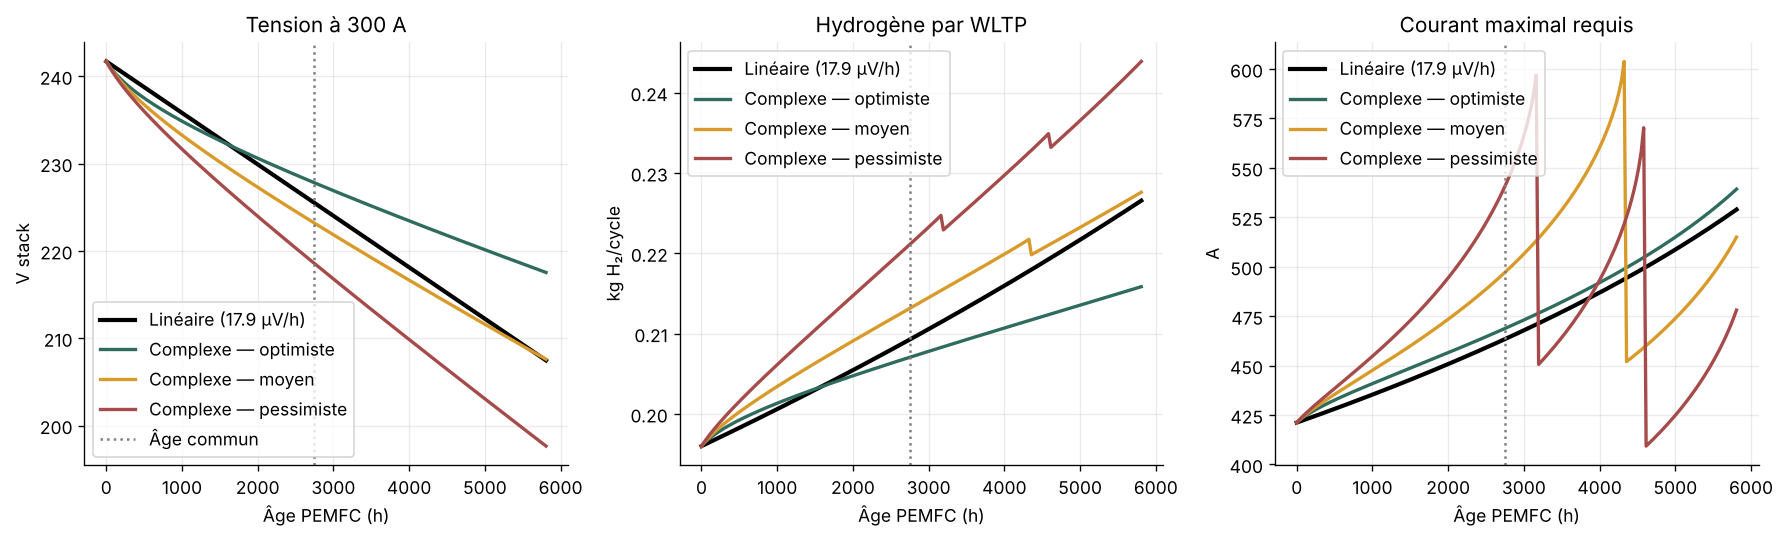

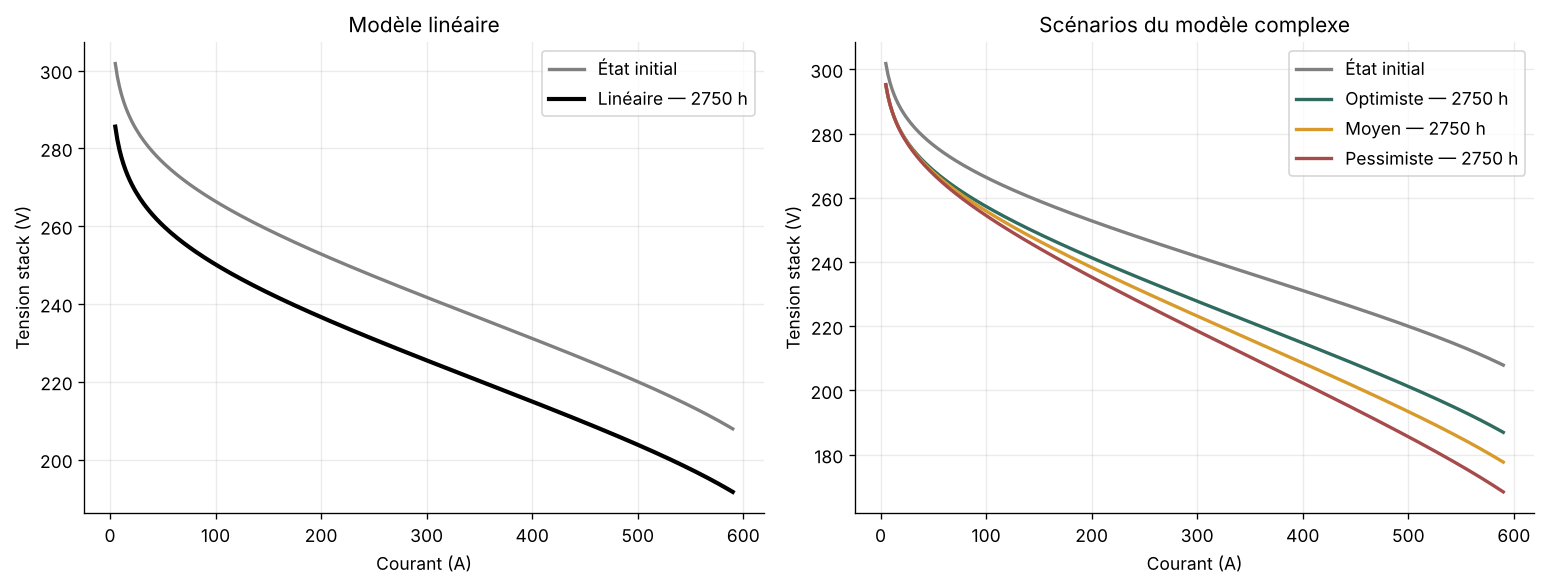

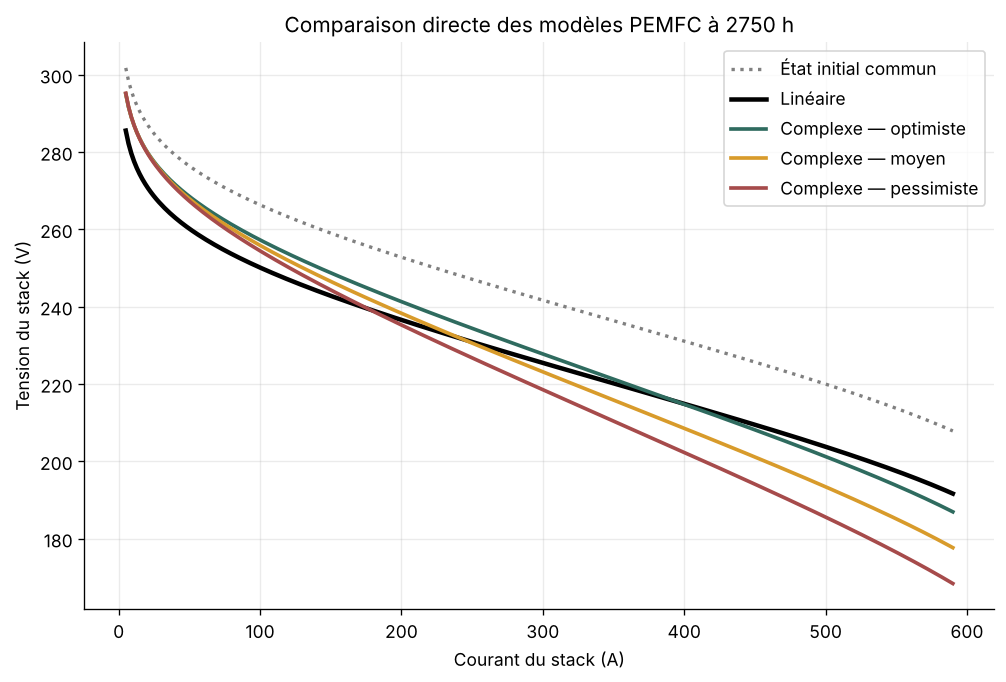

,Modèle,Scénario,EoL_h
0,Linéaire,Taux constant 17.9 µV/h,4100.000000
1,Complexe,Optimiste,5807.952786
2,Complexe,Moyen,3827.896730
3,Complexe,Pessimiste,2894.516390


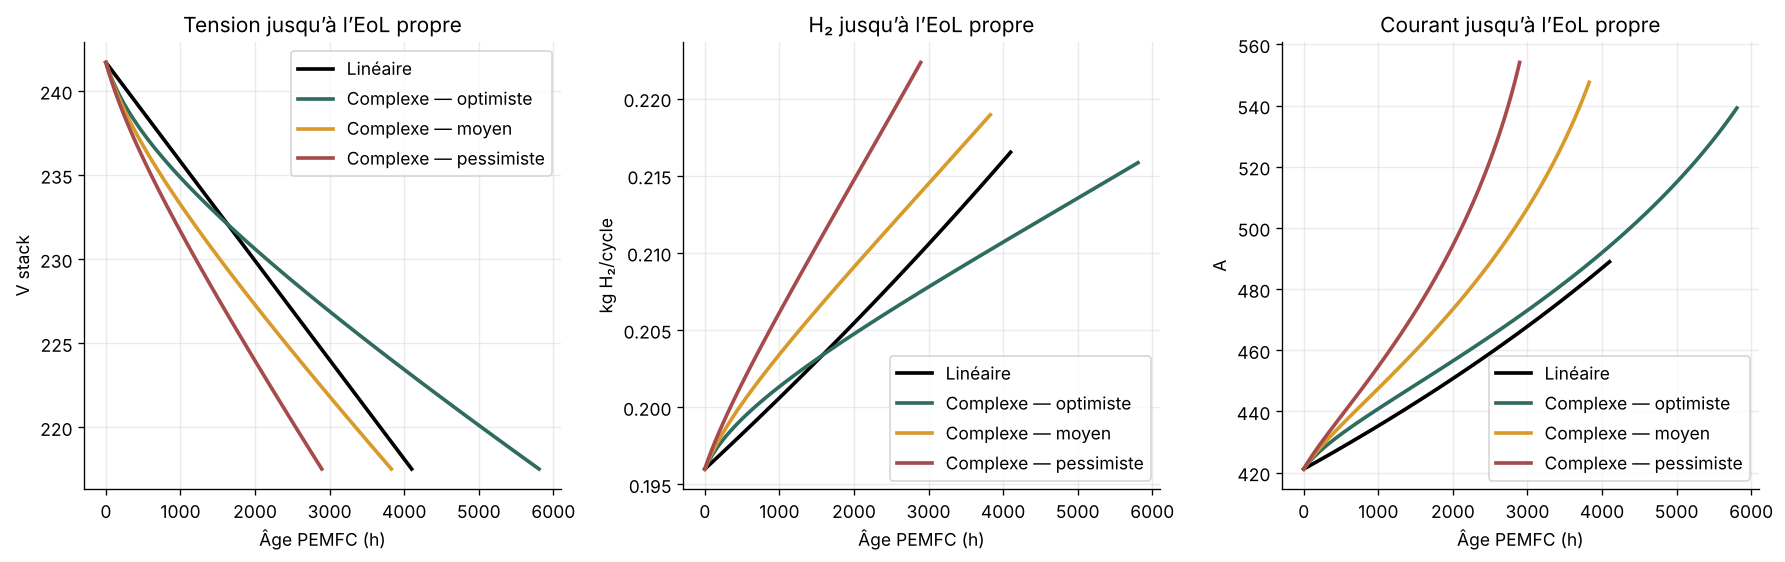

,Modèle,EoL_h,U300_EOL_V,H2_EOL_kg_cycle,Hausse_H2_EOL_pct,Imax_EOL_A
0,Linéaire,4100.000000,217.528425,0.216521,10.470038,488.960976
1,Complexe — optimiste,5807.952786,217.528425,0.215843,10.123987,539.226735
2,Complexe — moyen,3827.896730,217.528425,0.218950,11.709217,547.663862
3,Complexe — pessimiste,2894.516390,217.528425,0.222338,13.437700,554.121924


,Modèle,Âge_commun_h,EoL_h,Fraction_de_vie_pct,U300_V,H2_kg_cycle,Hausse_H2_pct,Imax_A
0,Linéaire,2749.790571,4100.000000,67.068063,225.488017,0.209259,6.765029,463.400341
1,Complexe — optimiste,2749.790571,5807.952786,47.345264,227.795212,0.207051,5.638379,468.768077
2,Complexe — moyen,2749.790571,3827.896730,71.835547,223.174735,0.213142,8.745969,497.144567
3,Complexe — pessimiste,2749.790571,2894.516390,95.000000,218.552219,0.221091,12.801638,540.674704


In [4]:
ages_fc_cmp=np.linspace(0,max([fc_eol_simple,*fc_eol_scenarios.values()]),181)
fc_cmp=[]
for a in ages_fc_cmp:
    row={'Age_h':a};qs=fc_state_simple(a)
    row.update({'U300_Linéaire':qs['U300'],'H2_Linéaire':qs['H2'],'Imax_Linéaire':qs['Imax']})
    for name,p in FC_COMPLEX_SCENARIOS.items():
        q=fc_state(a,p)
        row.update({f'U300_{name}':q['U300'],f'H2_{name}':q['H2'],f'Imax_{name}':q['Imax']})
    fc_cmp.append(row)
fc_cmp=pd.DataFrame(fc_cmp)
fig,axs=plt.subplots(1,3,figsize=(15,4.6))
for ax,prefix,ylab,title in zip(axs,['U300','H2','Imax'],['V stack','kg H₂/cycle','A'],
                               ['Tension à 300 A','Hydrogène par WLTP','Courant maximal requis']):
    ax.plot(fc_cmp.Age_h,fc_cmp[f'{prefix}_Linéaire'],label=f'Linéaire ({1e6*KDEG_FC:.1f} µV/h)',lw=2.5,color='black')
    for name in ['Optimiste','Moyen','Pessimiste']:
        ax.plot(fc_cmp.Age_h,fc_cmp[f'{prefix}_{name}'],label=f'Complexe — {name.lower()}',lw=2,color=COL[name])
    ax.axvline(AGE_FC_MAIN,color='grey',ls=':',label='Âge commun' if ax is axs[0] else None)
    ax.set(xlabel='Âge PEMFC (h)',ylabel=ylab,title=title);ax.legend()
fig.tight_layout();fig.savefig(OUT/'CMP_01_PEMFC_trajectoires.png',dpi=220);plt.show()

Igrid=np.linspace(5,590,300)
fig,axs=plt.subplots(1,2,figsize=(13,5))
axs[0].plot(Igrid,fc_U_simple(Igrid,0),label='État initial',lw=2,color='grey')
axs[0].plot(Igrid,fc_U_simple(Igrid,AGE_FC_MAIN),label=f'Linéaire — {AGE_FC_MAIN:.0f} h',lw=2.5,color='black')
axs[0].set_title('Modèle linéaire')
axs[1].plot(Igrid,fc_U(Igrid,0,FC_CENTRAL),label='État initial',lw=2,color='grey')
for name,p in FC_COMPLEX_SCENARIOS.items():
    axs[1].plot(Igrid,fc_U(Igrid,AGE_FC_MAIN,p),label=f'{name} — {AGE_FC_MAIN:.0f} h',lw=2,color=COL[name])
axs[1].set_title('Scénarios du modèle complexe')
for ax in axs:ax.set(xlabel='Courant (A)',ylabel='Tension stack (V)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'CMP_02_PEMFC_polarisation.png',dpi=220);plt.show()

# Comparaison directe sur une seule figure à l'âge commun.
fig,ax=plt.subplots(figsize=(8.5,5.8))
ax.plot(Igrid,fc_U_simple(Igrid,0),label='État initial commun',lw=2,color='grey',ls=':')
ax.plot(Igrid,fc_U_simple(Igrid,AGE_FC_MAIN),label='Linéaire',lw=2.7,color='black')
for name,p in FC_COMPLEX_SCENARIOS.items():
    ax.plot(Igrid,fc_U(Igrid,AGE_FC_MAIN,p),label=f'Complexe — {name.lower()}',lw=2.2,color=COL[name])
ax.set(xlabel='Courant du stack (A)',ylabel='Tension du stack (V)',
       title=f'Comparaison directe des modèles PEMFC à {AGE_FC_MAIN:.0f} h')
ax.legend();fig.tight_layout();fig.savefig(OUT/'CMP_02b_PEMFC_comparaison_directe.png',dpi=220);plt.show()

eol_fc_table=pd.DataFrame([
    {'Modèle':'Linéaire','Scénario':f'Taux constant {1e6*KDEG_FC:.1f} µV/h','EoL_h':fc_eol_simple},
    *[{'Modèle':'Complexe','Scénario':name,'EoL_h':life} for name,life in fc_eol_scenarios.items()]
])
display(eol_fc_table)

# ------------------------------------------------------------------
# Analyse A — chaque modèle est suivi jusqu'à sa propre fin de vie.
# Les courbes s'arrêtent à leur EoL respective.
# ------------------------------------------------------------------
fc_model_specs=[
    ('Linéaire',fc_eol_simple,lambda t:fc_state_simple(t),'black'),
    *[(f'Complexe — {name.lower()}',fc_eol_scenarios[name],
       lambda t,p=p:fc_state(t,p),COL[name])
      for name,p in FC_COMPLEX_SCENARIOS.items()]
]
fc_endpoint_rows=[]
fig,axs=plt.subplots(1,3,figsize=(15,4.8))
for label,life,statefun,color in fc_model_specs:
    ag=np.linspace(0,life,121)
    vals=[statefun(a) for a in ag]
    u=np.array([q['U300'] for q in vals]);h=np.array([q['H2'] for q in vals]);im=np.array([q['Imax'] for q in vals])
    axs[0].plot(ag,u,lw=2.2,label=label,color=color)
    axs[1].plot(ag,h,lw=2.2,label=label,color=color)
    axs[2].plot(ag,im,lw=2.2,label=label,color=color)
    q0=statefun(0);qe=statefun(life)
    fc_endpoint_rows.append({'Modèle':label,'EoL_h':life,'U300_EOL_V':qe['U300'],
                             'H2_EOL_kg_cycle':qe['H2'],
                             'Hausse_H2_EOL_pct':pct(qe['H2'],q0['H2']),
                             'Imax_EOL_A':qe['Imax']})
for ax,ylab,title in zip(axs,['V stack','kg H₂/cycle','A'],
                         ['Tension jusqu’à l’EoL propre','H₂ jusqu’à l’EoL propre','Courant jusqu’à l’EoL propre']):
    ax.set(xlabel='Âge PEMFC (h)',ylabel=ylab,title=title);ax.legend()
fig.tight_layout();fig.savefig(OUT/'CMP_02c_PEMFC_jusqua_EOL_propre.png',dpi=220);plt.show()
fc_endpoints=pd.DataFrame(fc_endpoint_rows);display(fc_endpoints)

# ------------------------------------------------------------------
# Analyse B — comparaison équitable au même âge de 3 000 h.
# ------------------------------------------------------------------
fc_common_rows=[]
for label,life,statefun,color in fc_model_specs:
    q0=statefun(0);q=statefun(AGE_FC_MAIN)
    fc_common_rows.append({'Modèle':label,'Âge_commun_h':AGE_FC_MAIN,'EoL_h':life,
                           'Fraction_de_vie_pct':100*AGE_FC_MAIN/life,
                           'U300_V':q['U300'],'H2_kg_cycle':q['H2'],
                           'Hausse_H2_pct':pct(q['H2'],q0['H2']),'Imax_A':q['Imax']})
fc_common=pd.DataFrame(fc_common_rows);display(fc_common)


# Partie II — PEMWE

## 5. Modèle complexe de référence

Le modèle complexe représente la perte d'activité de l'anode (décroissance exponentielle vers un plateau, convertie en tension avec la pente de Tafel mesurée, 46 mV/déc ; Padgett et al., 2025), la croissance des résistances HFR et de couche catalytique (Padgett et al., 2025) et la baisse du rendement faradique due à l'amincissement de la membrane (Chandesris et al., 2015). Les constantes sont celles d'un empilement de type commercial (Ti revêtu, IrO₂).

In [5]:
# ---------------------------------------------------------------- état neuf du PEMWE
# Lu dans pemwe_parametres.json, écrit par le notebook AB_vieillissement_PEMWE (exécuter celui-ci d'abord).
# Cinétique : alpha_a issu de la pente de Tafel mesurée (46 mV/déc, Padgett et al. 2025) ; cathode négligée ; E_rev(T).
import json as _json
from pathlib import Path as _Path
_PJ=next((p for p in [_Path("pemwe_parametres.json"),_Path("resultats_PEMWE_temperature_vieillissement")/"pemwe_parametres.json"] if p.exists()),None)
if _PJ is None: raise FileNotFoundError("pemwe_parametres.json introuvable : exécuter d'abord AB_vieillissement_PEMWE et placer le fichier à côté de ce notebook.")
PEMWE_P=_json.load(open(_PJ,encoding="utf-8"))
WE_T=PEMWE_P["T_K"];WE_R0=PEMWE_P["R0"];WE_ETAF0=PEMWE_P["etaF0"]
WE_E0=PEMWE_P["E0"];WE_H20=PEMWE_P["H20"];WE_SEC0=WE_E0/WE_H20;WE_V0=PEMWE_P["Vmean0"]
# Fin de vie (DOE) : +10 % de tension au courant de référence, le courant moyen du profil (j_ref).
WE_VREF0=PEMWE_P["Vref0"]
WE_W0=PEMWE_P["W0"];WE_WJ=PEMWE_P["Wj"];WE_JMEAN=PEMWE_P["j_ref"]
# Conversion activité -> tension : pente de Tafel mesurée par Padgett et al. (2025), identique à celle du modèle neuf.
WE_BTAF=PEMWE_P["b_tafel"];WE_CDEG=WE_BTAF/np.log(10)
print(f"PEMWE (fichier {_PJ}) : R0={1e3*WE_R0:.1f} mOhm.cm2 ; V_ref(0)={WE_VREF0:.4f} V ; SEC0={WE_SEC0:.3f} kWh/kg")

# ---------------------------------------------------------------- constantes issues de la littérature
# Padgett et al., J. Electrochem. Soc. 172 (2025) 054508 — 4000 h à 3 A/cm², 80 °C, 0,4 mgIr/cm² :
#   activité massique (IrO2 amorphe qui cristallise) : plateau 10,4/93, temps 1,0 kh ;
#   capacité (proxy de la surface active seule) : plateau 0,49, temps 1,1 kh ;
#   HFR : 7 µV/h à 3 A/cm² ; couche catalytique (CLR) : 3,4 µV/h à 3 A/cm² (liée à la dissolution d'Ir).
PADGETT={"fA_masse":10.4/93,"k_masse":1/1000.,"fA_capa":.49,"k_capa":1/1100.,"dHFR":7e-6/3.0,"dCLR":3.4e-6/3.0}
# Cas de stress (sensibilité seulement, non représentatifs d'un empilement commercial) :
RAKOUSKY_R=12e-6/2.0   # Rakousky et al. 2016 : 12 µV/h à 2 A/cm², 80 °C (toute la dérive attribuée à R)
PAPA_R=43.5e-6         # Papakonstantinou et al. 2020 : 43,5 µΩ.cm²/h, 60 °C, Ti non revêtu (cas de stress)
# Chandesris et al., Int. J. Hydrogen Energy 40 (2015) 1353 : 50 % d'amincissement à 353 K (80 °C) en 110 100 h (modèle linéaire)
#   et 80 700 h (modèle couplé) ; à 333 K (60 °C) : 590 500 h et 380 500 h (sensibilité).
CHANDESRIS_T50={"lineaire":110100.,"couple":80700.}
CHANDESRIS_T50_60C={"lineaire":590500.,"couple":380500.}
# Points de validation (non utilisés pour caler) : DOE 2022 4,8 µV/h (40 000 h) ; DOE 2026 2,3 µV/h (80 000 h) ;
#   Siracusano et al. (cité par Maoulida et al. 2026) : ~5 µV/h à 1,6 mg/cm², ~15 µV/h à 0,5 mg/cm².
WE_VALID={"DOE 2026 (cible)":2.3,"DOE 2022 (état)":4.8,"Siracusano, 1,6 mg/cm²":5.0,"Siracusano, 0,5 mg/cm²":15.0}

def we_params(fA_min,k_cat,r,t50):
    return {"fA_min":fA_min,"k_cat":k_cat,"k_R":r/WE_R0,"t50_mem":t50,"eol_frac":.10}
_mid=lambda a,b:.5*(a+b)
# V18 : seul le jeu « Pessimiste » est utilisé dans l'étude (cas pessimiste) ; « Optimiste » et « Moyen » sont gardés pour mémoire.
WE_SCEN={"Optimiste":we_params(PADGETT["fA_capa"],PADGETT["k_capa"],PADGETT["dHFR"],CHANDESRIS_T50["lineaire"]),
         "Moyen":we_params(_mid(PADGETT["fA_capa"],PADGETT["fA_masse"]),_mid(PADGETT["k_capa"],PADGETT["k_masse"]),
                           PADGETT["dHFR"]+.5*PADGETT["dCLR"],_mid(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"])),
         "Pessimiste":we_params(PADGETT["fA_masse"],PADGETT["k_masse"],PADGETT["dHFR"]+PADGETT["dCLR"],CHANDESRIS_T50["couple"])}
WE_CENTRAL=WE_SCEN["Moyen"]

def we_state(t,p):
 t=np.asarray(t,float);fa=p["fA_min"]+(1-p["fA_min"])*np.exp(-p["k_cat"]*t)
 # crossover proportionnel à 1/épaisseur ; épaisseur e/e0 = 1 - 0,5 t/t50 (Chandesris et al., 2015)
 eta=1-(1-WE_ETAF0)/(1-0.5*t/p["t50_mem"])
 dv=p.get('b',WE_BTAF)/np.log(10)*(-np.log(fa));vm=WE_V0+dv+WE_R0*p["k_R"]*t*WE_JMEAN
 en=WE_E0+dv*WE_W0+WE_R0*p["k_R"]*t*WE_WJ;h=WE_H20*eta/WE_ETAF0
 return {"fA":fa,"Rratio":1+p["k_R"]*t,"etaF":eta,"Vmean":vm,"Vref":WE_VREF0+(vm-WE_V0),"Energy":en,"H2":h,"SEC":en/h}
def we_eol(p,maxh=400000):
 # tension au courant de référence j_ref = WE_JMEAN : V_ref(t) = V_ref(0) + ΔV_cin + R0 k_R t j_ref
 g=lambda t:float(we_state(t,p)["Vref"]-(1+p["eol_frac"])*WE_VREF0)
 return brentq(g,0,maxh) if g(maxh)>=0 else np.nan
display(pd.DataFrame({n:{"f_A,min":p["fA_min"],"k_cat (1/h)":p["k_cat"],"dR/dt (mOhm.cm²/kh)":1e6*p["k_R"]*WE_R0,
  "k_R (1/h)":p["k_R"],"t50 membrane (h)":p["t50_mem"],"EoL (h)":we_eol(p)} for n,p in WE_SCEN.items()}).T)
print(f"PEMWE central : EoL={we_eol(WE_CENTRAL):.1f} h ; SEC0={WE_SEC0:.4f} kWh/kg")
print("Taux moyens équivalents (µV/h) = 10 % V_ref / EoL :",{n:round(1e6*.10*WE_VREF0/we_eol(p),2) for n,p in WE_SCEN.items()},"— références :",WE_VALID)

PEMWE (fichier pemwe_parametres.json) : R0=215.5 mOhm.cm2 ; V_ref(0)=1.8600 V ; SEC0=53.676 kWh/kg


,"f_A,min",k_cat (1/h),dR/dt (mOhm.cm²/kh),k_R (1/h),t50 membrane (h),EoL (h)
Optimiste,0.490000,0.000909,2.333333,0.000011,110100.0,61311.455642
Moyen,0.300914,0.000955,2.900000,0.000013,95400.0,46533.275923
Pessimiste,0.111828,0.001000,3.466667,0.000016,80700.0,34175.406934


PEMWE central : EoL=46533.3 h ; SEC0=53.6756 kWh/kg
Taux moyens équivalents (µV/h) = 10 % V_ref / EoL : {'Optimiste': 3.03, 'Moyen': 4.0, 'Pessimiste': 5.44} — références : {'DOE 2026 (cible)': 2.3, 'DOE 2022 (état)': 4.8, 'Siracusano, 1,6 mg/cm²': 5.0, 'Siracusano, 0,5 mg/cm²': 15.0}


## 6. Modèle linéaire PEMWE

Le modèle simple ajoute une dérive uniforme à la tension initiale :

$$V_{simple,m}(t)=V_m(0)+\mu_{WE}t.$$

Le courant expérimental est conservé. L'énergie de chaque seconde est donc corrigée par le rapport de tension. Le rendement faradique reste à sa valeur initiale. Le taux de 4,8 µV/h (DOE, état 2022) est appliqué directement, sans tenir compte de la densité de courant du profil : c'est la différence de structure avec le modèle complexe.

In [6]:
KDEG_WE=4.8e-6 # V/cell/h : DOE, état 2022 (4,8 mV/kh)

# Scénarios complexes : constantes de Padgett et al. 2025, Rakousky et al. 2016, Chandesris et al. 2015.
WE_COMPLEX_SCENARIOS={k:v.copy() for k,v in WE_SCEN.items()}
def we_state_simple(t):
    t=np.asarray(t,float)
    vm=WE_V0+KDEG_WE*t
    en=WE_E0+KDEG_WE*t*WE_W0
    h=np.zeros_like(t)+WE_H20
    return {'Vmean':vm,'Energy':en,'H2':h,'SEC':en/h,'etaF':np.zeros_like(t)+WE_ETAF0}

we_eol_simple=0.10*WE_VREF0/KDEG_WE
we_eol_scenarios={name:float(we_eol(p)) for name,p in WE_COMPLEX_SCENARIOS.items()}
we_eol_complex=we_eol_scenarios['Moyen']
AGE_WE_MAIN=15000.
print(f'EoL simple PEMWE   : {we_eol_simple:.1f} h')
for name,life in we_eol_scenarios.items():
    print(f'EoL complexe PEMWE {name.lower():11s}: {life:.1f} h')
print(f'Âge commun PEMWE   : {AGE_WE_MAIN:.0f} h')
assert AGE_WE_MAIN<min([we_eol_simple,*we_eol_scenarios.values()])


EoL simple PEMWE   : 38750.1 h
EoL complexe PEMWE optimiste  : 61311.5 h
EoL complexe PEMWE moyen      : 46533.3 h
EoL complexe PEMWE pessimiste : 34175.4 h
Âge commun PEMWE   : 15000 h


### Valeurs PEMWE utilisées dans la comparaison

Les durées de vie sont calculées dans la cellule précédente. Le modèle linéaire applique 4,8 µV/h (DOE, état 2022) au profil ; le modèle complexe applique les constantes de Padgett et al. (2025) à la densité de courant réelle du profil.

L'âge commun de comparaison est fixé à **15 000 h**, inférieur à toutes les fins de vie.

## 7. Résultats PEMWE

Les deux modèles partent exactement du même état initial. Le modèle simple ne peut produire qu'une hausse régulière de tension et de SEC. Le modèle complexe peut modifier simultanément la tension et la masse nette d'hydrogène.

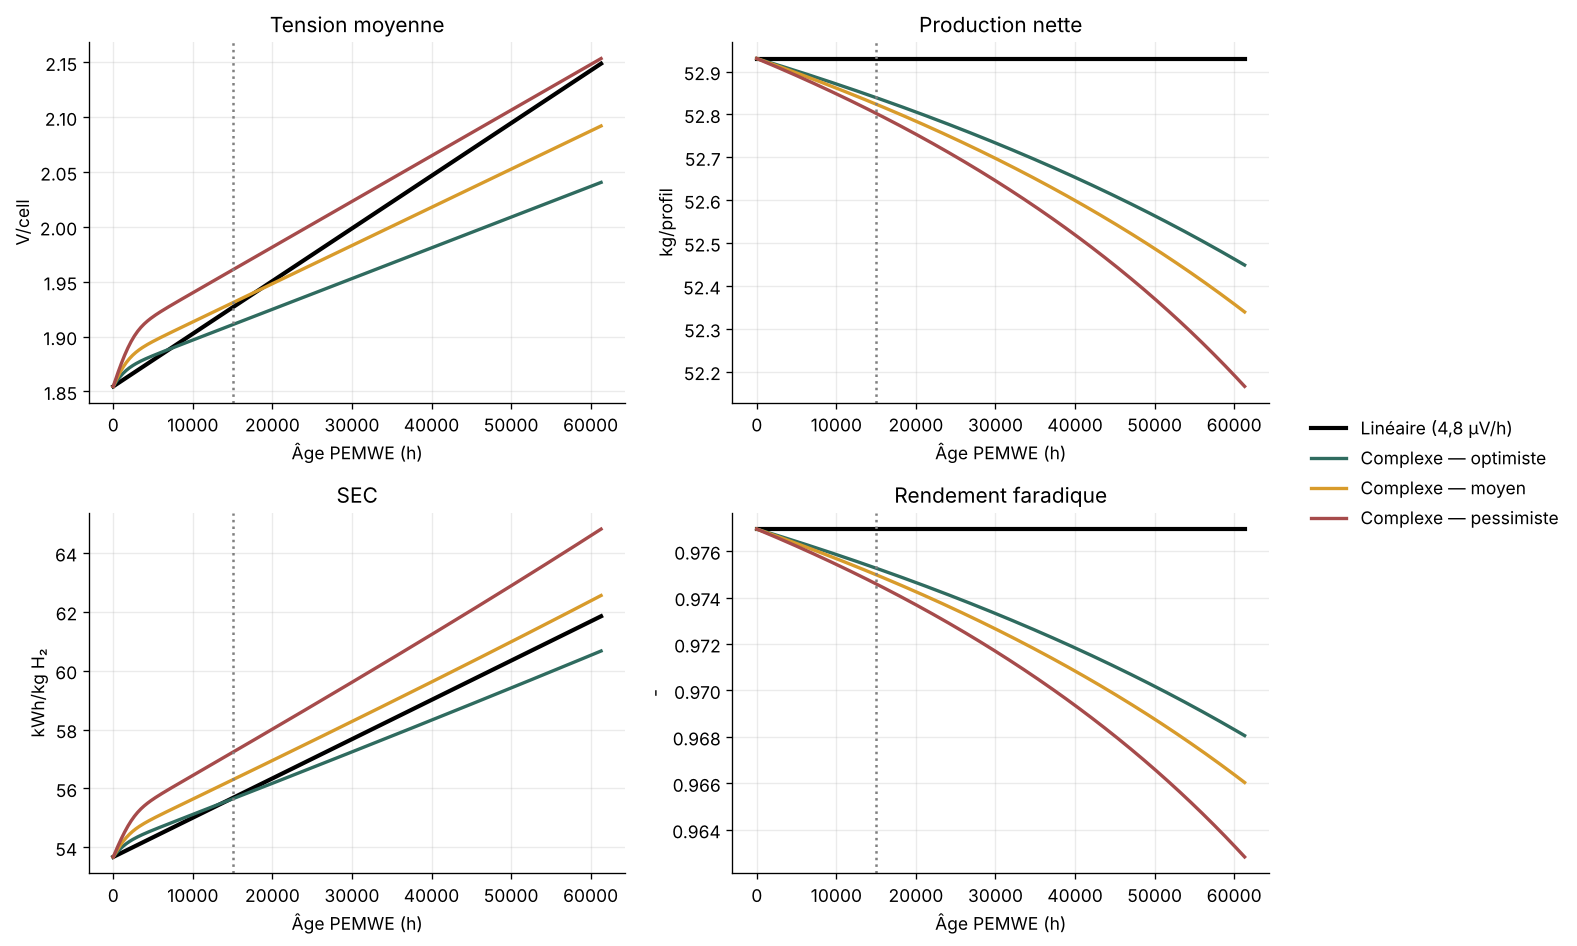

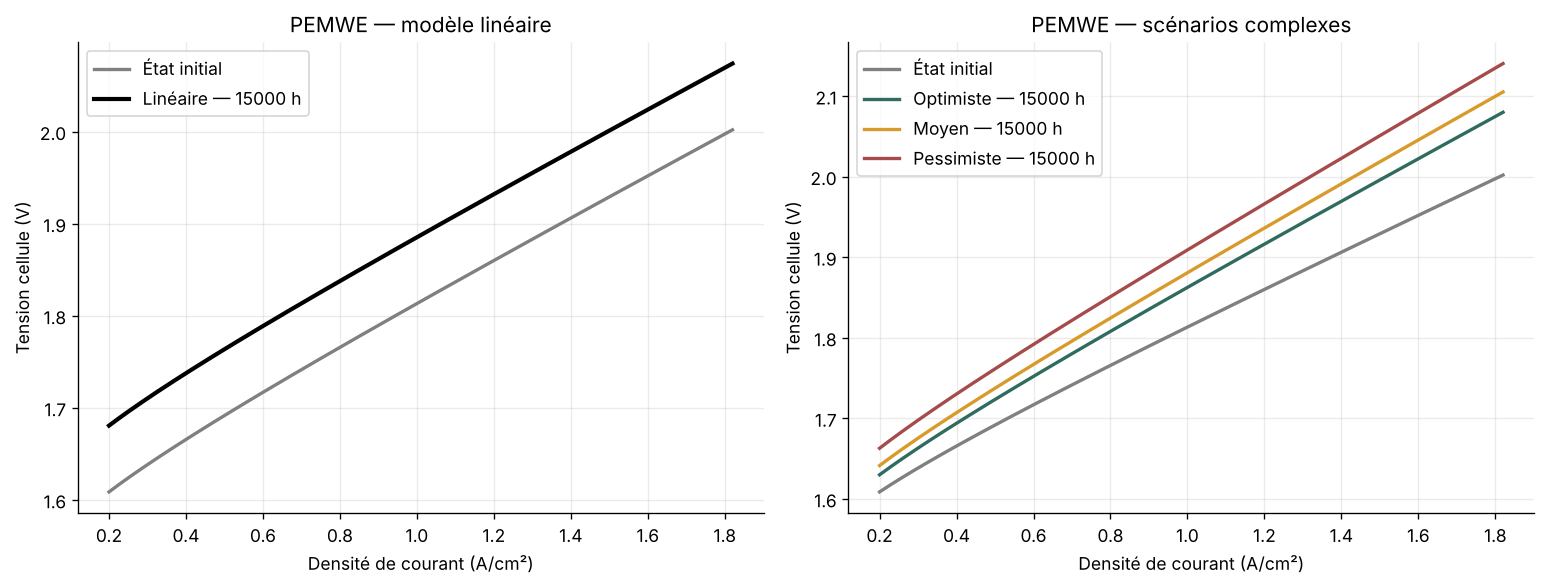

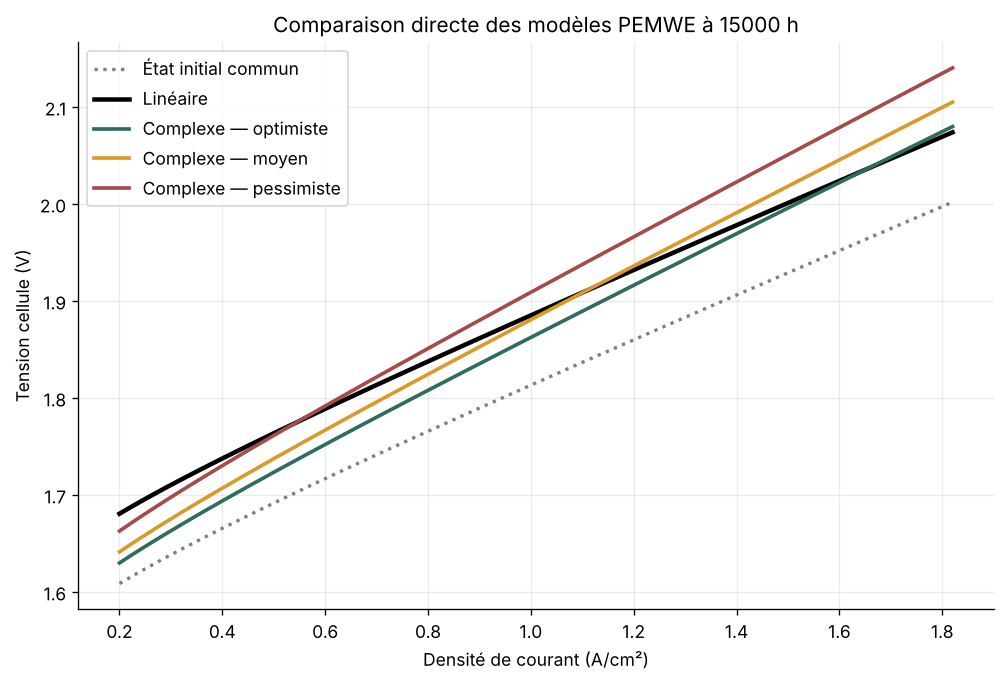

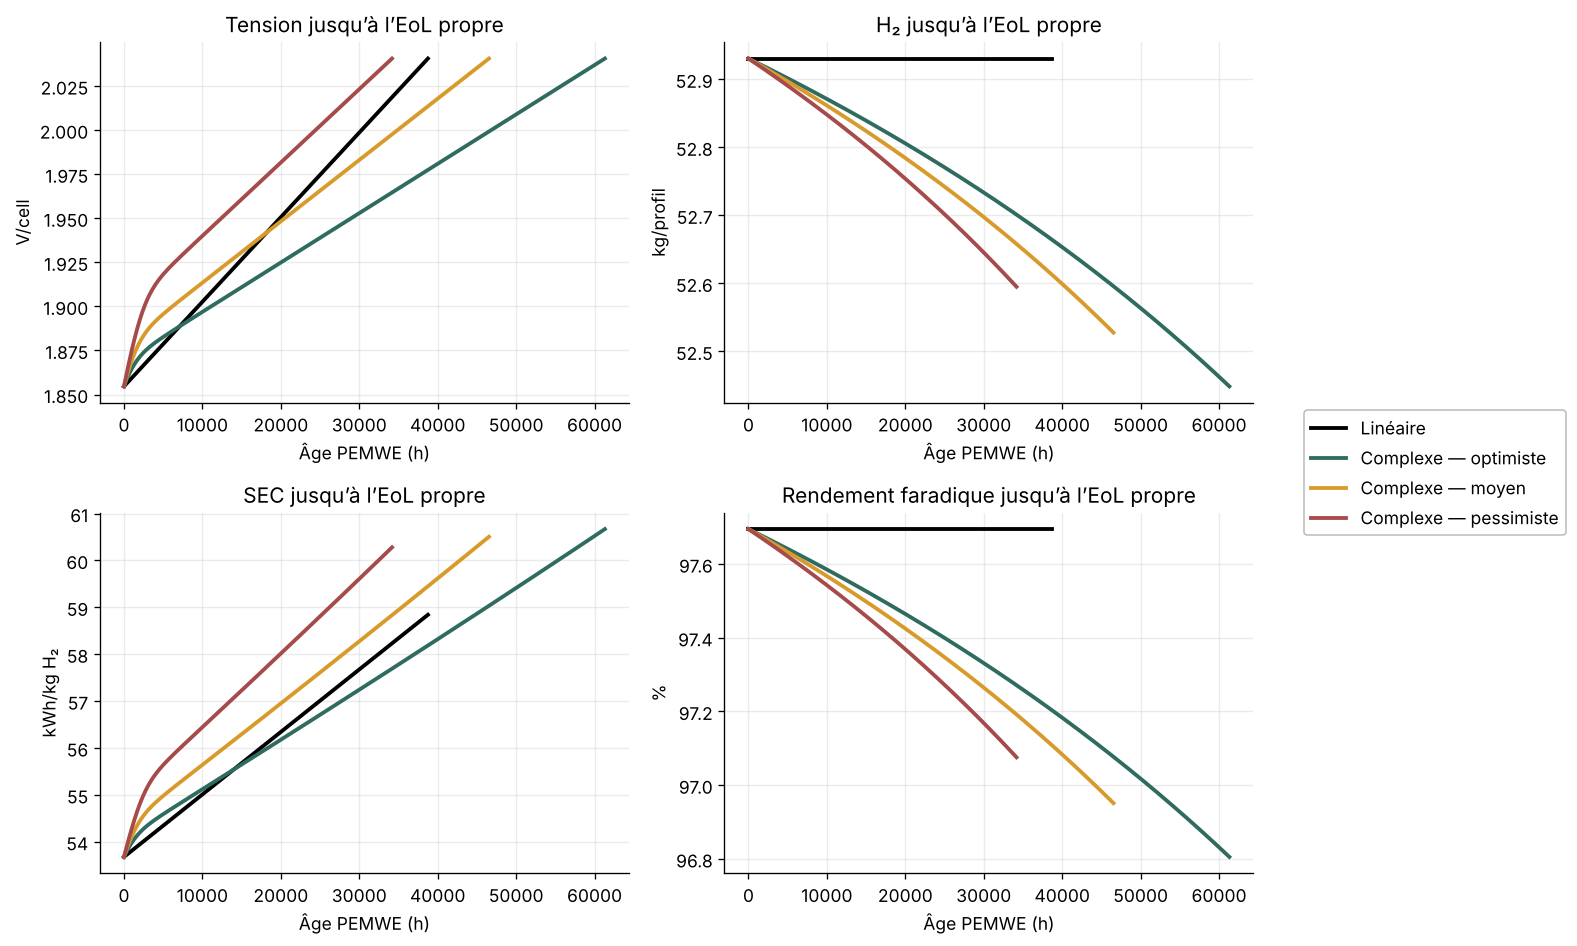

,Modèle,EoL_h,Vmean_EOL_V,H2_EOL_kg_profil,SEC_EOL_kWh_kg,Hausse_SEC_EOL_pct,EtaF_EOL_pct
0,Linéaire,38750.116025,2.040617,52.930524,58.841382,9.623986,97.694879
1,Complexe — optimiste,61311.455642,2.040617,52.448601,60.669205,13.029298,96.805385
2,Complexe — moyen,46533.275923,2.040617,52.527690,60.504967,12.723316,96.951361
3,Complexe — pessimiste,34175.406934,2.040617,52.595041,60.279698,12.303631,97.075671


,Modèle,Âge_commun_h,EoL_h,Fraction_de_vie_pct,Vmean_V,H2_kg_profil,SEC_kWh_kg,Hausse_SEC_pct,EtaF_pct
0,Linéaire,15000.0,38750.116025,38.709562,1.926616,52.930524,55.675279,3.725403,97.694879
1,Complexe — optimiste,15000.0,61311.455642,24.465249,1.910886,52.839230,55.646430,3.671657,97.526376
2,Complexe — moyen,15000.0,46533.275923,32.234997,1.930832,52.823962,56.293499,4.877173,97.498196
3,Complexe — pessimiste,15000.0,34175.406934,43.891211,1.960811,52.802563,57.226911,6.616159,97.458698


In [7]:
ages_we_cmp=np.linspace(0,max([we_eol_simple,*we_eol_scenarios.values()]),301)
qs=we_state_simple(ages_we_cmp)
we_data={'Age_h':ages_we_cmp,'V_Linéaire':qs['Vmean'],'H2_Linéaire':qs['H2'],
         'SEC_Linéaire':qs['SEC'],'etaF_Linéaire':qs['etaF']}
for name,p in WE_COMPLEX_SCENARIOS.items():
    q=we_state(ages_we_cmp,p)
    we_data.update({f'V_{name}':q['Vmean'],f'H2_{name}':q['H2'],
                    f'SEC_{name}':q['SEC'],f'etaF_{name}':q['etaF']})
we_cmp=pd.DataFrame(we_data)
fig,axs=plt.subplots(2,2,figsize=(13,8))
for ax,prefix,y,title in zip(axs.flat,['V','H2','SEC','etaF'],
                            ['V/cell','kg/profil','kWh/kg H₂','-'],['Tension moyenne','Production nette','SEC','Rendement faradique']):
    ax.plot(we_cmp.Age_h,we_cmp[f'{prefix}_Linéaire'],label='Linéaire (4,8 µV/h)',lw=2.5,color='black')
    for name in ['Optimiste','Moyen','Pessimiste']:
        ax.plot(we_cmp.Age_h,we_cmp[f'{prefix}_{name}'],label=f'Complexe — {name.lower()}',lw=2,color=COL[name])
    ax.axvline(AGE_WE_MAIN,color='grey',ls=':');ax.set(xlabel='Âge PEMWE (h)',ylabel=y,title=title)
# Une seule légende commune, placée hors des axes pour ne masquer aucune courbe.
handles,labels=axs[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='center left',bbox_to_anchor=(.835,.5),frameon=False)
fig.tight_layout(rect=[0,0,.83,1])
fig.savefig(OUT/'CMP_03_PEMWE_trajectoires.png',dpi=220,bbox_inches='tight');plt.show()

# Courbes de polarisation reconstruites à 0 et 30 000 h.
Erev_we=PEMWE_P["Erev"];i0a_we=PEMWE_P["i0a"];Bc_we=PEMWE_P["Bc"];ilim_we=PEMWE_P["ilim"];aa_we=PEMWE_P["alpha_a"]
def we_v0_grid(j):
    return Erev_we+R*WE_T/(2*F*aa_we)*np.log(j/i0a_we)+WE_R0*j-Bc_we*np.log1p(-j/ilim_we)
def we_v_simple_grid(j,t):return we_v0_grid(j)+KDEG_WE*t
def we_v_complex_grid(j,t,p):
    fa=p['fA_min']+(1-p['fA_min'])*np.exp(-p['k_cat']*t)
    return we_v0_grid(j)+WE_CDEG*(-np.log(fa))+WE_R0*p['k_R']*t*j
jgrid=np.linspace(.2,1.82,300)
fig,axs=plt.subplots(1,2,figsize=(13,5))
axs[0].plot(jgrid,we_v_simple_grid(jgrid,0),label='État initial',lw=2,color='grey')
axs[0].plot(jgrid,we_v_simple_grid(jgrid,AGE_WE_MAIN),label=f'Linéaire — {AGE_WE_MAIN:.0f} h',lw=2.5,color='black')
axs[1].plot(jgrid,we_v_complex_grid(jgrid,0,WE_CENTRAL),label='État initial',lw=2,color='grey')
for name,p in WE_COMPLEX_SCENARIOS.items():
    axs[1].plot(jgrid,we_v_complex_grid(jgrid,AGE_WE_MAIN,p),label=f'{name} — {AGE_WE_MAIN:.0f} h',lw=2,color=COL[name])
axs[0].set_title('PEMWE — modèle linéaire');axs[1].set_title('PEMWE — scénarios complexes')
for ax in axs:ax.set(xlabel='Densité de courant (A/cm²)',ylabel='Tension cellule (V)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'CMP_04_PEMWE_polarisation.png',dpi=220);plt.show()

# Comparaison directe des quatre modèles à l'âge commun.
fig,ax=plt.subplots(figsize=(8.5,5.8))
ax.plot(jgrid,we_v_simple_grid(jgrid,0),label='État initial commun',lw=2,color='grey',ls=':')
ax.plot(jgrid,we_v_simple_grid(jgrid,AGE_WE_MAIN),label='Linéaire',lw=2.7,color='black')
for name,p in WE_COMPLEX_SCENARIOS.items():
    ax.plot(jgrid,we_v_complex_grid(jgrid,AGE_WE_MAIN,p),label=f'Complexe — {name.lower()}',lw=2.2,color=COL[name])
ax.set(xlabel='Densité de courant (A/cm²)',ylabel='Tension cellule (V)',
       title=f'Comparaison directe des modèles PEMWE à {AGE_WE_MAIN:.0f} h')
ax.legend();fig.tight_layout();fig.savefig(OUT/'CMP_04a_PEMWE_comparaison_directe.png',dpi=220);plt.show()

# Analyse A — chaque modèle PEMWE jusqu'à sa propre EoL.
we_model_specs=[('Linéaire',we_eol_simple,we_state_simple,'black'),
                *[(f'Complexe — {name.lower()}',we_eol_scenarios[name],
                   lambda t,p=p:we_state(t,p),COL[name])
                  for name,p in WE_COMPLEX_SCENARIOS.items()]]
we_endpoint_rows=[]
fig,axs=plt.subplots(2,2,figsize=(13,8))
for label,life,statefun,color in we_model_specs:
    ag=np.linspace(0,life,301);q=statefun(ag)
    for ax,key in zip(axs.flat,['Vmean','H2','SEC','etaF']):ax.plot(ag,q[key],lw=2.3,label=label,color=color)
    q0=statefun(np.array([0.]));qe=statefun(np.array([life]))
    we_endpoint_rows.append({'Modèle':label,'EoL_h':life,'Vmean_EOL_V':float(qe['Vmean'][0]),
                             'H2_EOL_kg_profil':float(qe['H2'][0]),
                             'SEC_EOL_kWh_kg':float(qe['SEC'][0]),
                             'Hausse_SEC_EOL_pct':pct(float(qe['SEC'][0]),float(q0['SEC'][0])),
                             'EtaF_EOL_pct':100*float(qe['etaF'][0])})
for ax,ylab,title in zip(axs.flat,['V/cell','kg/profil','kWh/kg H₂','%'],
                         ['Tension jusqu’à l’EoL propre','H₂ jusqu’à l’EoL propre',
                          'SEC jusqu’à l’EoL propre','Rendement faradique jusqu’à l’EoL propre']):
    ax.set(xlabel='Âge PEMWE (h)',ylabel=ylab,title=title)
for line in axs[1,1].lines:line.set_ydata(100*line.get_ydata())
axs[1,1].relim();axs[1,1].autoscale_view()

# Une seule légende commune, placée à droite en dehors des quatre axes.
# Elle ne recouvre donc aucune courbe.
handles,labels=axs[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='center left',bbox_to_anchor=(.835,.5),
           frameon=True,facecolor='white',edgecolor='#B0B0B0')
fig.tight_layout(rect=[0,0,.82,1])
fig.savefig(OUT/'CMP_04b_PEMWE_jusqua_EOL_propre.png',dpi=220,bbox_inches='tight');plt.show()
we_endpoints=pd.DataFrame(we_endpoint_rows);display(we_endpoints)

# Analyse B — les deux modèles au même âge.
we_common_rows=[]
for label,life,statefun,color in we_model_specs:
    q0=statefun(np.array([0.]));q=statefun(np.array([AGE_WE_MAIN]))
    we_common_rows.append({'Modèle':label,'Âge_commun_h':AGE_WE_MAIN,'EoL_h':life,
                           'Fraction_de_vie_pct':100*AGE_WE_MAIN/life,
                           'Vmean_V':float(q['Vmean'][0]),'H2_kg_profil':float(q['H2'][0]),
                           'SEC_kWh_kg':float(q['SEC'][0]),
                           'Hausse_SEC_pct':pct(float(q['SEC'][0]),float(q0['SEC'][0])),
                           'EtaF_pct':100*float(q['etaF'][0])})
we_common=pd.DataFrame(we_common_rows);display(we_common)


# Partie III — Comparaison ACV

## 8. Inventaires environnementaux

Les 16 catégories EF 3.1, l'électricité, l'eau et la compression sont identiques dans les deux modèles. Pour le PEMWE seul, l'unité fonctionnelle est 1 kg H₂ net. Pour la PEMFC et la chaîne, elle est 1 véhicule-km.

In [8]:
IND=["Acidification","Changement climatique","Écotoxicité totale","Écotoxicité inorganique","Écotoxicité organique","Énergie fossile","Eutrophisation eau douce","Eutrophisation marine","Eutrophisation terrestre","Toxicité humaine totale","Toxicité humaine inorganique","Toxicité humaine organique","Ressources minérales","Ozone","Utilisation de l'eau","Particules",'Usage des terres','Radiations ionisantes',"Formation photochimique d'ozone",'Toxicité humaine non cancérigène']
# V7 : électricité « electricity, medium voltage, residual mix, FR » (ecoinvent 3.11), 79,6 g CO2-éq/kWh ; 1 kg H2 à SEC0 = 53,68 kWh
PEMWE0=pd.Series([0.014080271731083883,4.279518514616187,9.216274764335342,9.018659489438866,0.19761527489647454,751.1485348419133,0.0006020793013419391,0.005360203204265161,0.03607825778601173,1.2622317905119135e-09,5.764367453553225e-10,6.857950451565908e-10,3.5110621382400735e-05,1.2921747933230577e-07,6.915084079752976,2.435753146253289e-07,18.37154927146217,34.21778334049153,0.013218293055706492,4.6241096630620186e-08],index=IND)
EAU=pd.Series([4.3015400209306186e-5,.004733269280060789,.5163586472916831,.5155973630639497,.0007612842277334075,.05653778154903194,2.0440058578679185e-6,4.7512683456755126e-6,4.944502800990178e-5,9.699031513101342e-12,1.8535308388814734e-12,7.84550067421987e-12,1.892943055533071e-7,1.6052450945239224e-9,.008718816055577004,3.4746999298301196e-10,0.019804603536997124,0.00032295113797400286,1.688266617734751e-05,1.4053860329714182e-10],index=IND)
COMP3=pd.Series([.0007845600949876251,.23892317979233288,.4862493677029604,.47524694800089473,.011002419702065676,41.97948620928328,3.3536735194147435e-5,.00029932301444871235,.0020136961307415362,7.000564762886212e-11,3.21141860441632e-11,3.789146158469892e-11,1.9517973486203604e-6,7.132409942174174e-9,.3860055312509987,1.3594313332347568e-8,1.0257023310308786,1.9124573449770381,0.0007378436031262743,2.5766187730964955e-09],index=IND)
FE=(PEMWE0-EAU)/WE_SEC0;GWP="Changement climatique"
DIST=20.32349744662911;DUR=0.5644303275925;HFC_AN=(200000./15.)/DIST*DUR   # 200 000 km sur 15 ans (Toyota, Takahashi et al. 2022)
E_COMP=2.8   # kWh d'électricité par kg comprimé (Magnaval et al. 2026) ; COMP3 = impact de 3 kWh, mis à l'échelle par comp/3
def impactkg(sec,loss=0,comp=E_COMP,cf=1):return (sec*FE*cf+EAU+COMP3*(comp/3))/(1-loss)
print("Climat initial chaîne =",impactkg(WE_SEC0)[GWP],"kg CO2-éq/kg H2 livré")


Climat initial chaîne = 4.502513482422365 kg CO2-éq/kg H2 livré


## 9. Deux niveaux d'analyse ACV

La lecture des résultats suit deux étapes complémentaires :

1. **jusqu'à l'EoL propre de chaque modèle**, afin de décrire complètement chaque trajectoire ;
2. **à âge commun**, afin de comparer les modèles de manière équitable.

Les impacts cumulés sur des durées de vie différentes sont des résultats propres à chaque modèle, mais ils ne constituent pas une comparaison directe. La comparaison principale repose sur le même âge, le même profil et le même service.

### 9.1 Calcul à âge commun

Pour la PEMFC seule, le kilogramme d'hydrogène conserve son impact initial afin d'isoler l'effet du modèle de pile. Pour le PEMWE seul :

$$IC^{WE}_{k,kgH_2}(t)=SEC(t)FE_{elec,k}+IC_{eau,k}.$$

L'écart structurel est calculé par :

$$\Delta_{structure,k}=100\left(\frac{IC_{complexe,k}}{IC_{simple,k}}-1\right).$$

,Système,Indicateur,Âge_h,Impact_simple,Impact_complexe,Écart_complexe_vs_simple_pct
0,PEMFC,Acidification,2749.790571,1.525161e-04,1.553460e-04,1.855420
1,PEMWE,Acidification,15000.000000,1.460322e-02,1.476489e-02,1.107133
2,PEMFC,Changement climatique,2749.790571,4.635981e-02,4.721998e-02,1.855420
3,PEMWE,Changement climatique,15000.000000,4.438771e+00,4.488007e+00,1.109219
4,PEMFC,Écotoxicité totale,2749.790571,9.956758e-02,1.014150e-01,1.855420
5,PEMWE,Écotoxicité totale,15000.000000,9.540382e+00,9.640585e+00,1.050304
6,PEMFC,Écotoxicité inorganique,2749.790571,9.742711e-02,9.923480e-02,1.855420
7,PEMWE,Écotoxicité inorganique,15000.000000,9.335433e+00,9.433369e+00,1.049076
8,PEMFC,Écotoxicité organique,2749.790571,2.140465e-03,2.180180e-03,1.855420
9,PEMWE,Écotoxicité organique,15000.000000,2.049489e-01,2.072162e-01,1.106279


,Modèle,Âge_h,Indicateur,Impact_par_km,Écart_vs_linéaire_pct
0,Linéaire,2749.790571,Acidification,1.525161e-04,0.000000
1,Linéaire,2749.790571,Changement climatique,4.635981e-02,0.000000
2,Linéaire,2749.790571,Écotoxicité totale,9.956758e-02,0.000000
3,Linéaire,2749.790571,Écotoxicité inorganique,9.742711e-02,0.000000
4,Linéaire,2749.790571,Écotoxicité organique,2.140465e-03,0.000000
5,Linéaire,2749.790571,Énergie fossile,8.137571e+00,0.000000
6,Linéaire,2749.790571,Eutrophisation eau douce,6.521555e-06,0.000000
7,Linéaire,2749.790571,Eutrophisation marine,5.806745e-05,0.000000
8,Linéaire,2749.790571,Eutrophisation terrestre,3.908289e-04,0.000000
9,Linéaire,2749.790571,Toxicité humaine totale,1.366923e-11,0.000000


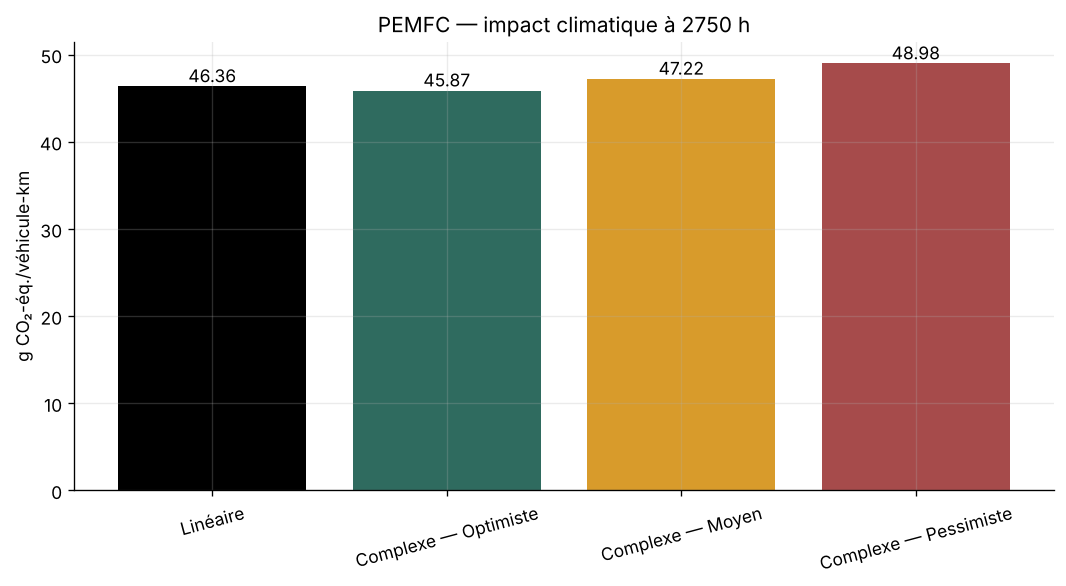

,Modèle,Âge_h,Indicateur,Impact_par_kgH2,Écart_vs_linéaire_pct
0,Linéaire,15000.0,Acidification,1.460322e-02,0.000000
1,Linéaire,15000.0,Changement climatique,4.438771e+00,0.000000
2,Linéaire,15000.0,Écotoxicité totale,9.540382e+00,0.000000
3,Linéaire,15000.0,Écotoxicité inorganique,9.335433e+00,0.000000
4,Linéaire,15000.0,Écotoxicité organique,2.049489e-01,0.000000
5,Linéaire,15000.0,Énergie fossile,7.791297e+02,0.000000
6,Linéaire,15000.0,Eutrophisation eau douce,6.244330e-04,0.000000
7,Linéaire,15000.0,Eutrophisation marine,5.559715e-03,0.000000
8,Linéaire,15000.0,Eutrophisation terrestre,3.742048e-02,0.000000
9,Linéaire,15000.0,Toxicité humaine totale,1.308894e-09,0.000000


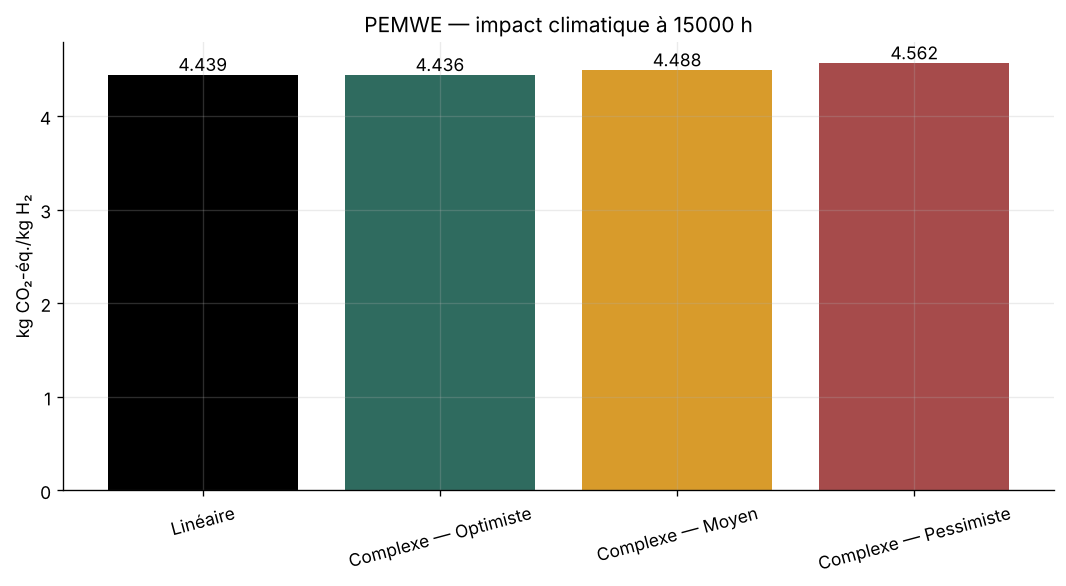

,Système,Modèle,EoL_h,Type_résultat,Indicateur,Impact
0,PEMFC,Linéaire,4100.000000,À l’EoL,Acidification,1.578088e-04
1,PEMFC,Linéaire,4100.000000,Moyenne sur la vie,Acidification,1.500589e-04
2,PEMFC,Linéaire,4100.000000,À l’EoL,Changement climatique,4.796861e-02
3,PEMFC,Linéaire,4100.000000,Moyenne sur la vie,Changement climatique,4.561289e-02
4,PEMFC,Linéaire,4100.000000,À l’EoL,Écotoxicité totale,1.030228e-01
5,PEMFC,Linéaire,4100.000000,Moyenne sur la vie,Écotoxicité totale,9.796341e-02
6,PEMFC,Linéaire,4100.000000,À l’EoL,Écotoxicité inorganique,1.008081e-01
7,PEMFC,Linéaire,4100.000000,Moyenne sur la vie,Écotoxicité inorganique,9.585743e-02
8,PEMFC,Linéaire,4100.000000,À l’EoL,Écotoxicité organique,2.214744e-03
9,PEMFC,Linéaire,4100.000000,Moyenne sur la vie,Écotoxicité organique,2.105979e-03


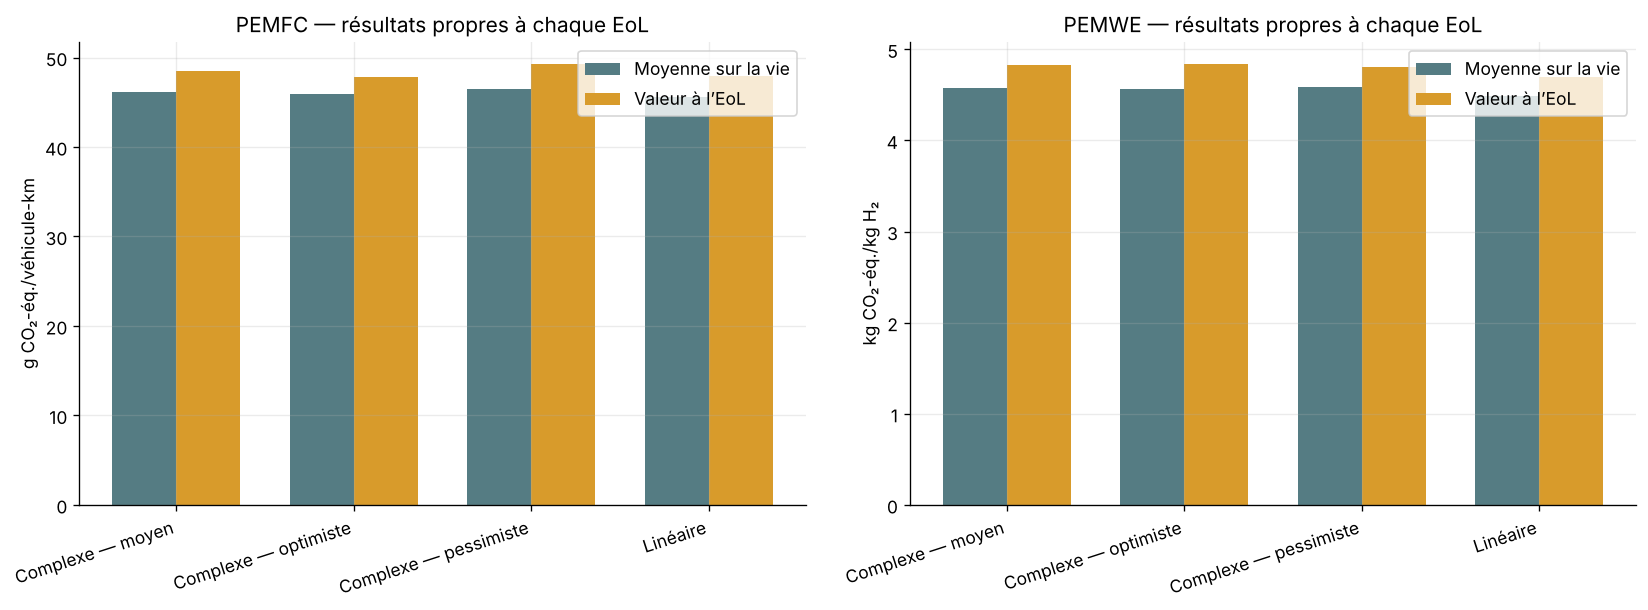

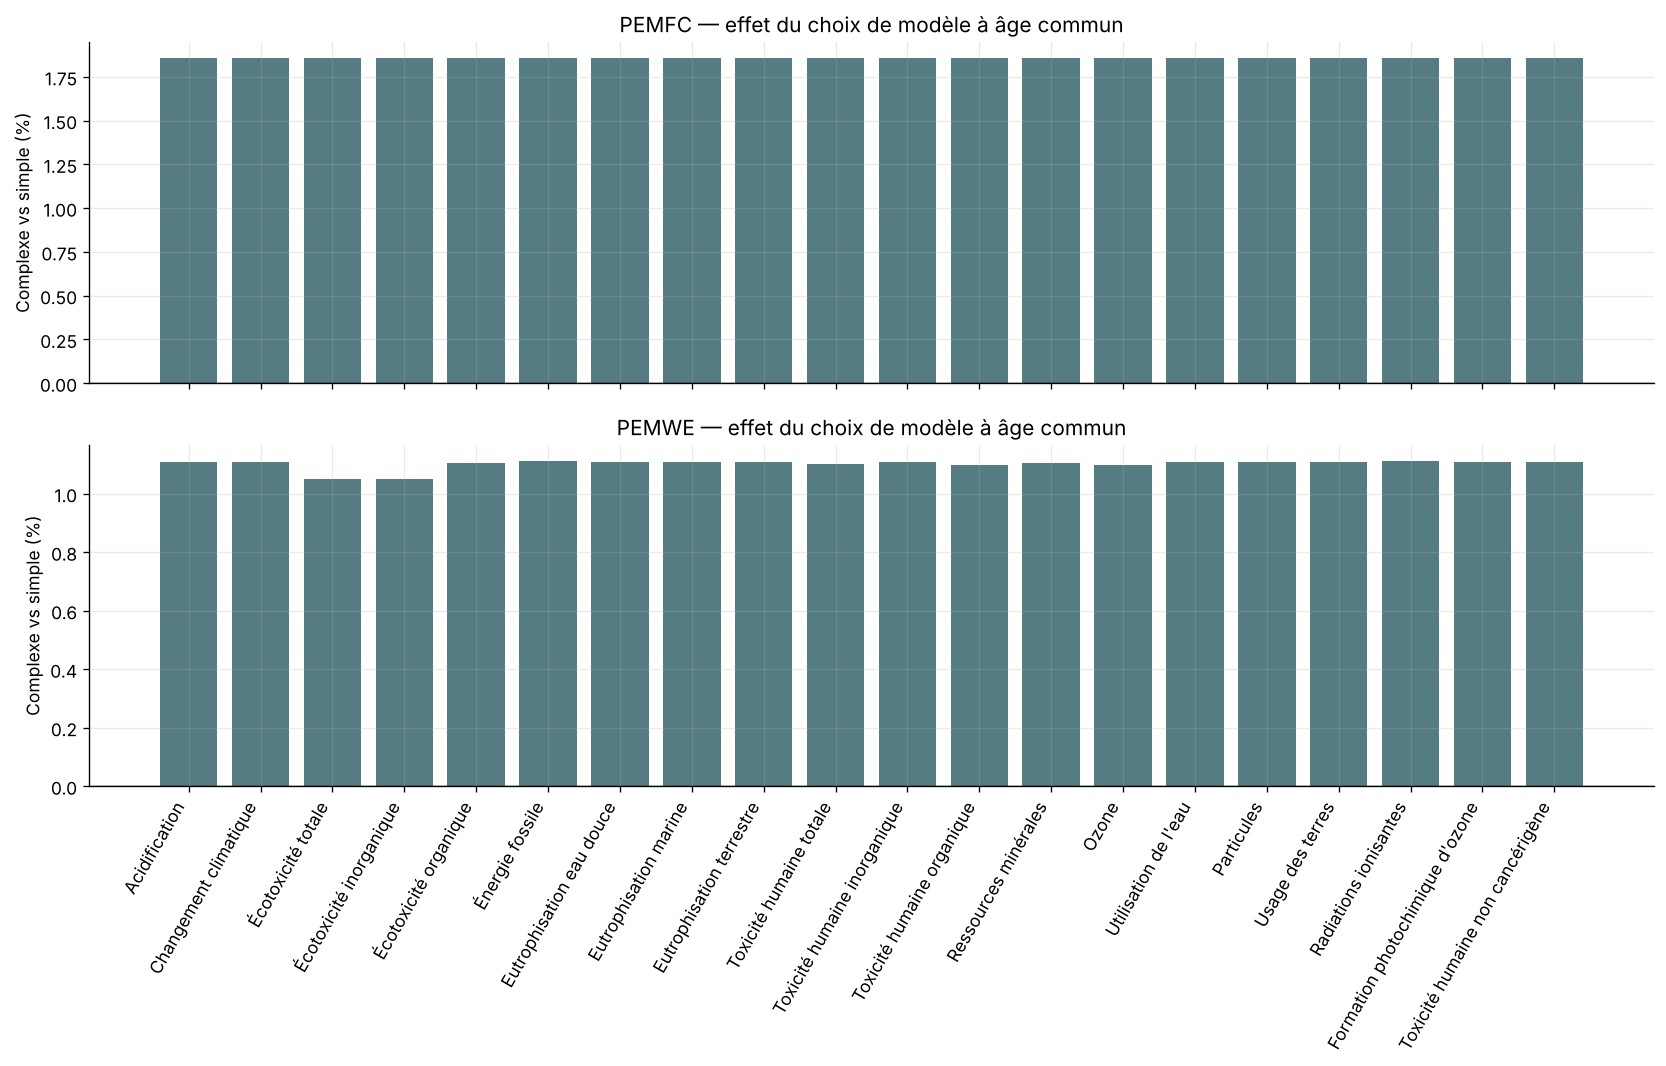

In [9]:
def impact_we_only(sec):return float(sec)*FE+EAU
h2_intensity0=impactkg(WE_SEC0)

# PEMFC à l'âge commun valide.
fc_s=fc_state_simple(AGE_FC_MAIN);fc_c=fc_state(AGE_FC_MAIN,FC_CENTRAL)
imp_fc_s=fc_s['H2']/DIST*h2_intensity0;imp_fc_c=fc_c['H2']/DIST*h2_intensity0
fc_states_all={'Linéaire':fc_s,**{f'Complexe — {name}':fc_state(AGE_FC_MAIN,p)
                                  for name,p in FC_COMPLEX_SCENARIOS.items()}}
fc_impacts_all={name:q['H2']/DIST*h2_intensity0 for name,q in fc_states_all.items()}

# PEMWE à 30 000 h.
we_s=we_state_simple(AGE_WE_MAIN);we_c=we_state(AGE_WE_MAIN,WE_CENTRAL)
imp_we_s=impact_we_only(float(we_s['SEC']));imp_we_c=impact_we_only(float(we_c['SEC']))
we_states_all={'Linéaire':we_s,**{f'Complexe — {name}':we_state(AGE_WE_MAIN,p)
                                  for name,p in WE_COMPLEX_SCENARIOS.items()}}
we_impacts_all={name:impact_we_only(float(q['SEC'])) for name,q in we_states_all.items()}

rows=[]
for ind in IND:
    rows += [
      {'Système':'PEMFC','Indicateur':ind,'Âge_h':AGE_FC_MAIN,'Impact_simple':imp_fc_s[ind],'Impact_complexe':imp_fc_c[ind],
       'Écart_complexe_vs_simple_pct':pct(imp_fc_c[ind],imp_fc_s[ind])},
      {'Système':'PEMWE','Indicateur':ind,'Âge_h':AGE_WE_MAIN,'Impact_simple':imp_we_s[ind],'Impact_complexe':imp_we_c[ind],
       'Écart_complexe_vs_simple_pct':pct(imp_we_c[ind],imp_we_s[ind])}]
acv_age_commun=pd.DataFrame(rows);display(acv_age_commun)

# Tableau complet PEMFC : linéaire versus les trois scénarios complexes.
acv_fc_scenarios=pd.DataFrame([
    {'Modèle':model,'Âge_h':AGE_FC_MAIN,'Indicateur':ind,
     'Impact_par_km':imp[ind],
     'Écart_vs_linéaire_pct':pct(imp[ind],fc_impacts_all['Linéaire'][ind])}
    for model,imp in fc_impacts_all.items() for ind in IND
])
display(acv_fc_scenarios)

qg=acv_fc_scenarios[acv_fc_scenarios.Indicateur==GWP]
fig,ax=plt.subplots(figsize=(9,5))
colors=['black',COL['Optimiste'],COL['Moyen'],COL['Pessimiste']]
ax.bar(qg['Modèle'],1e3*qg['Impact_par_km'],color=colors)
ax.set(ylabel='g CO₂-éq./véhicule-km',title=f'PEMFC — impact climatique à {AGE_FC_MAIN:.0f} h')
ax.tick_params(axis='x',rotation=15)
for i,v in enumerate(1e3*qg['Impact_par_km']):ax.text(i,v,f'{v:.2f}',ha='center',va='bottom')
fig.tight_layout();fig.savefig(OUT/'CMP_05b_ACV_PEMFC_scenarios.png',dpi=220);plt.show()

# Tableau complet PEMWE : linéaire versus les trois scénarios complexes.
acv_we_scenarios=pd.DataFrame([
    {'Modèle':model,'Âge_h':AGE_WE_MAIN,'Indicateur':ind,
     'Impact_par_kgH2':imp[ind],
     'Écart_vs_linéaire_pct':pct(imp[ind],we_impacts_all['Linéaire'][ind])}
    for model,imp in we_impacts_all.items() for ind in IND
])
display(acv_we_scenarios)

qg=acv_we_scenarios[acv_we_scenarios.Indicateur==GWP]
fig,ax=plt.subplots(figsize=(9,5))
ax.bar(qg['Modèle'],qg['Impact_par_kgH2'],color=['black',COL['Optimiste'],COL['Moyen'],COL['Pessimiste']])
ax.set(ylabel='kg CO₂-éq./kg H₂',title=f'PEMWE — impact climatique à {AGE_WE_MAIN:.0f} h')
ax.tick_params(axis='x',rotation=15)
for i,v in enumerate(qg['Impact_par_kgH2']):ax.text(i,v,f'{v:.3f}',ha='center',va='bottom')
fig.tight_layout();fig.savefig(OUT/'CMP_05d_ACV_PEMWE_scenarios.png',dpi=220);plt.show()

# Analyse A : chaque modèle jusqu'à sa propre EoL.
# On distingue la valeur instantanée à l'EoL de la moyenne intégrée sur la vie.
trapz_local=(getattr(np,'trapezoid',None) or np.trapz)
acv_own_life=[]
for label,life,statefun,color in fc_model_specs:
    ag=np.linspace(0,life,301)
    h=np.array([statefun(a)['H2'] for a in ag])
    h_eol=float(h[-1]);h_mean=float(trapz_local(h,ag)/life)
    for ind in IND:
        acv_own_life += [
          {'Système':'PEMFC','Modèle':label,'EoL_h':life,'Type_résultat':'À l’EoL',
           'Indicateur':ind,'Impact':h_eol/DIST*h2_intensity0[ind]},
          {'Système':'PEMFC','Modèle':label,'EoL_h':life,'Type_résultat':'Moyenne sur la vie',
           'Indicateur':ind,'Impact':h_mean/DIST*h2_intensity0[ind]}]

for label,life,statefun,color in we_model_specs:
    ag=np.linspace(0,life,301);q=statefun(ag)
    impacts=np.vstack([impact_we_only(float(sec)).to_numpy() for sec in q['SEC']])
    prod=np.asarray(q['H2'],float)/4.0
    avg=np.array([trapz_local(prod*impacts[:,k],ag)/trapz_local(prod,ag) for k in range(len(IND))])
    end=impacts[-1]
    for k,ind in enumerate(IND):
        acv_own_life += [
          {'Système':'PEMWE','Modèle':label,'EoL_h':life,'Type_résultat':'À l’EoL',
           'Indicateur':ind,'Impact':end[k]},
          {'Système':'PEMWE','Modèle':label,'EoL_h':life,'Type_résultat':'Moyenne sur la vie',
           'Indicateur':ind,'Impact':avg[k]}]

acv_own_life=pd.DataFrame(acv_own_life);display(acv_own_life)
fig,axs_eol=plt.subplots(1,2,figsize=(14,5.2))
for ax,sys,scale,unit in [(axs_eol[0],'PEMFC',1e3,'g CO₂-éq./véhicule-km'),
                          (axs_eol[1],'PEMWE',1.,'kg CO₂-éq./kg H₂')]:
    q=acv_own_life[(acv_own_life.Système==sys)&(acv_own_life.Indicateur==GWP)]
    pv=q.pivot(index='Modèle',columns='Type_résultat',values='Impact')
    x=np.arange(len(pv));w=.36
    ax.bar(x-w/2,scale*pv['Moyenne sur la vie'],w,label='Moyenne sur la vie',color='#557C83')
    ax.bar(x+w/2,scale*pv['À l’EoL'],w,label='Valeur à l’EoL',color='#D89B2B')
    ax.set_xticks(x,pv.index,rotation=18,ha='right');ax.set(ylabel=unit,title=f'{sys} — résultats propres à chaque EoL')
    ax.legend()
fig.tight_layout();fig.savefig(OUT/'CMP_05c_ACV_EOL_propres.png',dpi=220);plt.show()

fig,axs=plt.subplots(2,1,figsize=(14,9),sharex=True)
for ax,sys in zip(axs,['PEMFC','PEMWE']):
    q=acv_age_commun[acv_age_commun.Système==sys].set_index('Indicateur').loc[IND]
    ax.bar(np.arange(len(IND)),q['Écart_complexe_vs_simple_pct'],color='#557C83');ax.axhline(0,color='black',lw=.8)
    ax.set(ylabel='Complexe vs simple (%)',title=f'{sys} — effet du choix de modèle à âge commun')
axs[1].set_xticks(np.arange(len(IND)),IND,rotation=60,ha='right')
fig.tight_layout();fig.savefig(OUT/'CMP_05_ACV_elements_separes.png',dpi=220);plt.show()


## 10. Impacts cumulés à service et durée communs

Pour éviter de comparer deux durées de vie différentes, les impacts cumulés principaux sont intégrés sur le même horizon. La règle des trapèzes est utilisée. Les EoL propres sont fournies séparément comme résultats du modèle, mais ne servent pas directement à comparer les impacts absolus.

In [10]:
trapz=(getattr(np,'trapezoid',None) or np.trapz);cycles_h=1/DUR

# PEMFC, même horizon et même distance.
gfc=np.linspace(0,AGE_FC_MAIN,101)
hfc_s=np.array([fc_state_simple(a)['H2'] for a in gfc]);hfc_c=np.array([fc_state(a,FC_CENTRAL)['H2'] for a in gfc])

# PEMWE, même horizon de fonctionnement ; normalisation par la masse produite.
gwe=np.linspace(0,AGE_WE_MAIN,201);qws=we_state_simple(gwe);qwc=we_state(gwe,WE_CENTRAL);profile_h=4.

cum_rows=[]
for ind in IND:
    fc_is=float(trapz(cycles_h*hfc_s*h2_intensity0[ind],gfc));fc_ic=float(trapz(cycles_h*hfc_c*h2_intensity0[ind],gfc))
    is_we=np.array([impact_we_only(x)[ind] for x in qws['SEC']]);ic_we=np.array([impact_we_only(x)[ind] for x in qwc['SEC']])
    htot_s=float(trapz(qws['H2']/profile_h,gwe));htot_c=float(trapz(qwc['H2']/profile_h,gwe))
    we_is=float(trapz(qws['H2']/profile_h*is_we,gwe))/htot_s
    we_ic=float(trapz(qwc['H2']/profile_h*ic_we,gwe))/htot_c
    cum_rows += [
      {'Système':'PEMFC','Indicateur':ind,'Impact_simple':fc_is,'Impact_complexe':fc_ic,'Écart_pct':pct(fc_ic,fc_is)},
      {'Système':'PEMWE','Indicateur':ind,'Impact_simple':we_is,'Impact_complexe':we_ic,'Écart_pct':pct(we_ic,we_is)}]
acv_cum_compare=pd.DataFrame(cum_rows);display(acv_cum_compare)


,Système,Indicateur,Impact_simple,Impact_complexe,Écart_pct
0,PEMFC,Acidification,1.461112e+01,1.481915e+01,1.423776
1,PEMWE,Acidification,1.434174e-02,1.449273e-02,1.052781
2,PEMFC,Changement climatique,4.441293e+03,4.504527e+03,1.423776
3,PEMWE,Changement climatique,4.359145e+00,4.405125e+00,1.054801
4,PEMFC,Écotoxicité totale,9.538624e+03,9.674433e+03,1.423776
5,PEMWE,Écotoxicité totale,9.378328e+00,9.471906e+00,0.997809
6,PEMFC,Écotoxicité inorganique,9.333566e+03,9.466455e+03,1.423776
7,PEMWE,Écotoxicité inorganique,9.177046e+00,9.268507e+00,0.996621
8,PEMFC,Écotoxicité organique,2.050576e+02,2.079772e+02,1.423776
9,PEMWE,Écotoxicité organique,2.012821e-01,2.033995e-01,1.051954


## 11. Couplage : matrice du choix de modèle

À l'horizon commun PEMFC, quatre combinaisons sont évaluées :

| | PEMWE simple | PEMWE complexe |
|---|---:|---:|
| PEMFC simple | $M_{SS}$ | $M_{SC}$ |
| PEMFC complexe | $M_{CS}$ | $M_{CC}$ |

L'âge du PEMWE est obtenu par le même temps calendaire :

$$t_{WE}=\frac{t_{FC}}{H_{FC,an}}H_{WE,an},$$

avec 6 000 h/an pour le PEMWE. Cette matrice mesure directement l'influence du choix de modèle de chaque composant.

Âge de couplage : PEMFC 2004 h ; PEMWE 32467 h


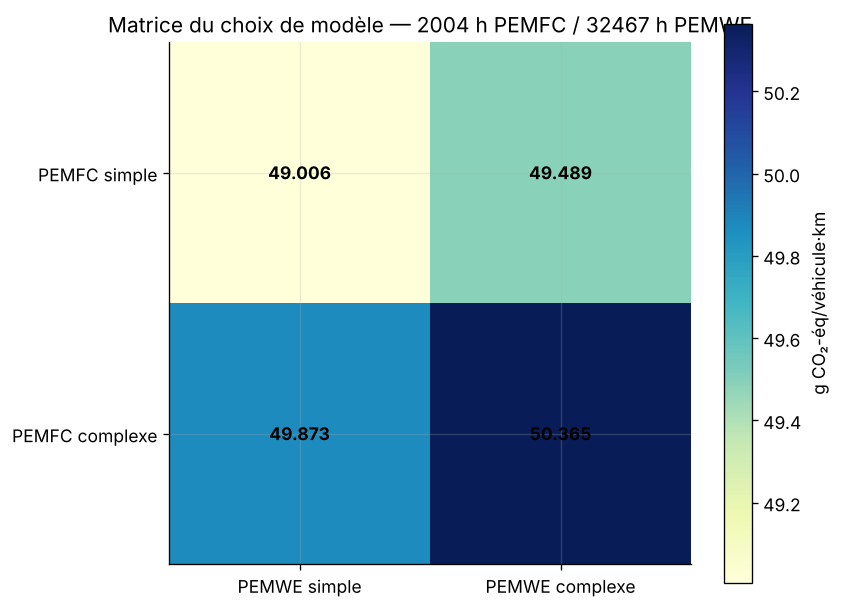

Modèle_PEMWE,Simple,Complexe
Modèle_PEMFC,,
Simple,49.005502,49.488978
Complexe,49.872528,50.364558


In [11]:
HWE_AN=6000.;# Âge commun de couplage : l'âge correspondant du PEMWE doit rester inférieur à 95 % de toutes ses fins de vie.
AGE_COUP_FC=min(AGE_FC_MAIN,.95*min([we_eol_simple,*we_eol_scenarios.values()])*HFC_AN/HWE_AN)
AGE_WE_COUP=AGE_COUP_FC/HFC_AN*HWE_AN
print(f'Âge de couplage : PEMFC {AGE_COUP_FC:.0f} h ; PEMWE {AGE_WE_COUP:.0f} h')
states_fc={'Simple':fc_state_simple(AGE_COUP_FC),'Complexe':fc_state(AGE_COUP_FC,FC_CENTRAL)}
states_we={'Simple':we_state_simple(AGE_WE_COUP),'Complexe':we_state(AGE_WE_COUP,WE_CENTRAL)}
rows=[]
for ind in IND:
    for lf,sf in states_fc.items():
        for lw,sw in states_we.items():
            val=sf['H2']/DIST*impactkg(float(sw['SEC']))[ind]
            rows.append({'Indicateur':ind,'Modèle_PEMFC':lf,'Modèle_PEMWE':lw,'Impact_par_km':val})
matrix_models=pd.DataFrame(rows)
mg=matrix_models[matrix_models.Indicateur==GWP].pivot(index='Modèle_PEMFC',columns='Modèle_PEMWE',values='Impact_par_km').loc[['Simple','Complexe'],['Simple','Complexe']]
fig,ax=plt.subplots(figsize=(7,5.5));im=ax.imshow(1000*mg.values,cmap='YlGnBu')
for i in range(2):
    for j in range(2):ax.text(j,i,f'{1000*mg.iloc[i,j]:.3f}',ha='center',va='center',fontweight='bold')
ax.set_xticks(range(2),['PEMWE simple','PEMWE complexe']);ax.set_yticks(range(2),['PEMFC simple','PEMFC complexe'])
ax.set_title(f'Matrice du choix de modèle — {AGE_COUP_FC:.0f} h PEMFC / {AGE_WE_COUP:.0f} h PEMWE')
fig.colorbar(im,ax=ax,label='g CO₂-éq/véhicule·km');fig.tight_layout();fig.savefig(OUT/'CMP_06_matrice_modeles_couplage.png',dpi=220);plt.show();display(mg*1000)


## 12. Rendements énergétiques du PEMWE, de la PEMFC et de la chaîne complète

Cette section complète l'analyse ACV par des indicateurs énergétiques. Le calcul est réalisé sur la base du **PCI de l'hydrogène**, fixé à :

$$PCI_{H_2}=33{,}33 mathrm{kWh,kg^{-1}}.$$

Le rendement énergétique du PEMWE est :

$$eta_{WE}(t)=rac{PCI_{H_2}}{SEC(t)}.$$

La SEC étant calculée à partir de la masse nette d'hydrogène, elle intègre déjà la perte de rendement faradique. Le rendement faradique n'est donc pas multiplié une seconde fois par le rendement énergétique.

Le rendement électrique de la PEMFC sur le cycle WLTP est :

$$eta_{FC}(t)=rac{E_{WLTP}}{m_{H_2,WLTP}(t),PCI_{H_2}},$$

où $E_{WLTP}$ est l'énergie électrique demandée par le véhicule pendant le cycle. Cette énergie reste identique pour tous les modèles, car le service de mobilité est conservé.

Le rendement global de la phase d'usage est :

$$eta_{chaîne}(t_{WE},t_{FC})=
rac{E_{WLTP}}
{m_{H_2,WLTP}(t_{FC}),[SEC(t_{WE})+E_{comp}]}.$$

La compression est fixée à $E_{comp}=2{,}8 mathrm{kWh,kg^{-1},H_2}$. Les pertes de stockage sont nulles dans le cas central. Ce rendement global ne comprend pas la fabrication des équipements : celle-ci reste comptabilisée dans l'ACV.

Deux lectures sont conservées :

1. évolution de chaque modèle jusqu'à sa propre EoL ;
2. comparaison à un âge commun, avec conversion calendaire pour le couplage PEMWE–PEMFC.


Energie utile du WLTP : 4.1896 kWh/cycle
Energie utile par km  : 0.2061 kWh/km
Rendement PEMWE initial (PCI) : 62.10 %
Rendement PEMFC initial (PCI) : 64.13 %
Rendement global initial avec compression : 37.72 %


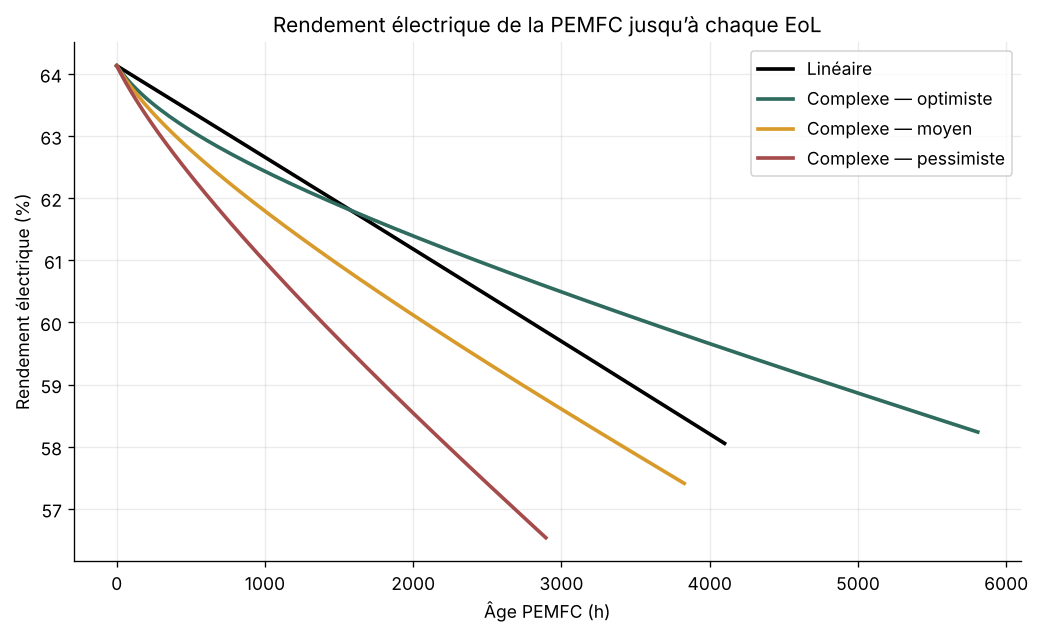

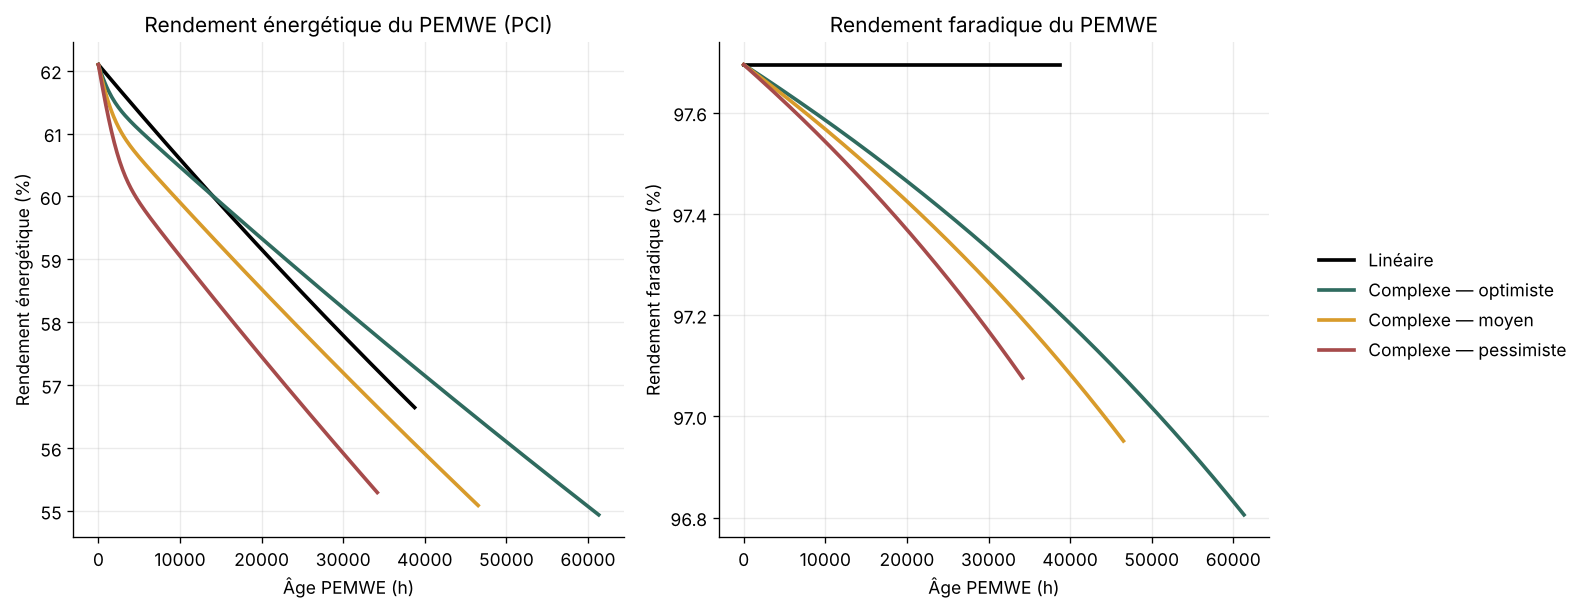

,Modèle_PEMFC,Modèle_PEMWE,Âge_PEMFC_h,Âge_PEMWE_h,Rendement_PEMFC_pct,Rendement_PEMWE_pct,Rendement_global_pct,EtaF_PEMWE_pct
0,Simple,Simple,2003.718,32466.637,61.176,57.462,33.424,97.695
1,Simple,Complexe — Optimiste,2003.718,32466.637,61.176,57.958,33.699,97.296
2,Simple,Complexe — Moyen,2003.718,32466.637,61.176,56.873,33.099,97.222
3,Simple,Complexe — Pessimiste,2003.718,32466.637,61.176,55.546,32.363,97.114
4,Complexe — Optimiste,Simple,2003.718,32466.637,61.389,57.462,33.540,97.695
5,Complexe — Optimiste,Complexe — Optimiste,2003.718,32466.637,61.389,57.958,33.816,97.296
6,Complexe — Optimiste,Complexe — Moyen,2003.718,32466.637,61.389,56.873,33.213,97.222
7,Complexe — Optimiste,Complexe — Pessimiste,2003.718,32466.637,61.389,55.546,32.476,97.114
8,Complexe — Moyen,Simple,2003.718,32466.637,60.113,57.462,32.843,97.695
9,Complexe — Moyen,Complexe — Optimiste,2003.718,32466.637,60.113,57.958,33.113,97.296


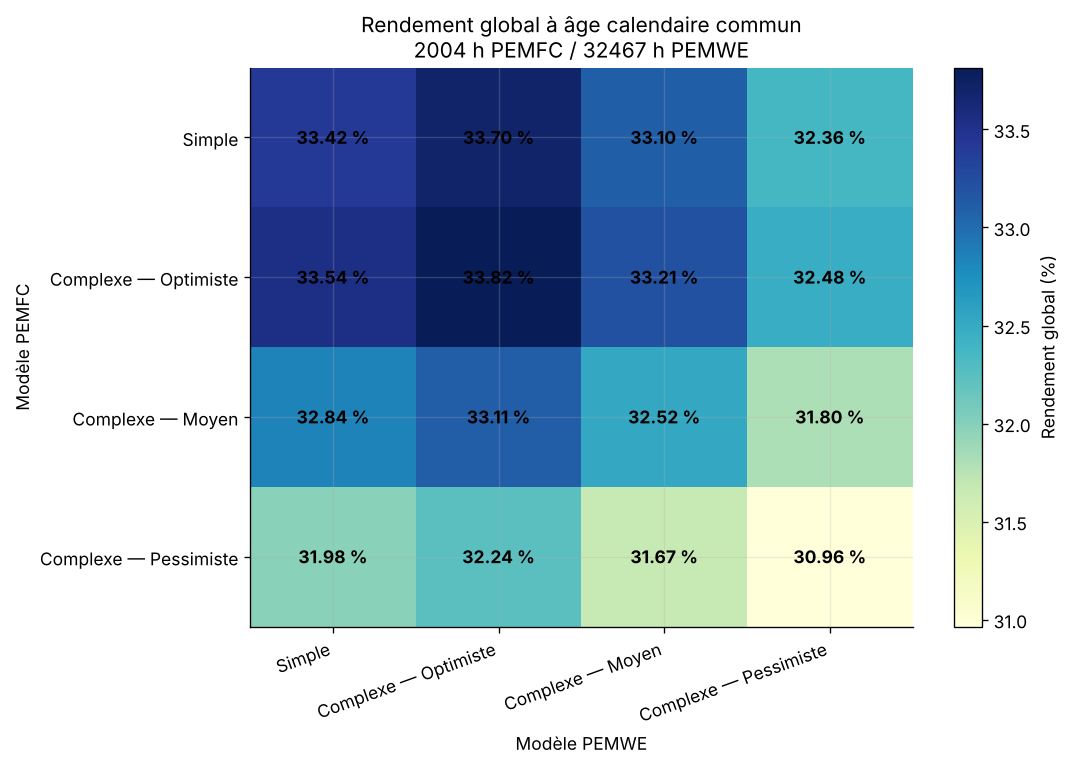

,Système,Modèle,État,Âge_h,Rendement_pct
0,PEMFC,Linéaire,Initial,0.000,64.133
1,PEMFC,Linéaire,EoL propre,4100.000,58.054
2,PEMFC,Complexe — optimiste,Initial,0.000,64.133
3,PEMFC,Complexe — optimiste,EoL propre,5807.953,58.237
4,PEMFC,Complexe — moyen,Initial,0.000,64.133
5,PEMFC,Complexe — moyen,EoL propre,3827.897,57.410
6,PEMFC,Complexe — pessimiste,Initial,0.000,64.133
7,PEMFC,Complexe — pessimiste,EoL propre,2894.516,56.536


,Système,Modèle,État,Âge_h,Rendement_énergétique_pct,Rendement_faradique_pct
0,PEMWE,Linéaire,Initial,0.000,62.095,97.695
1,PEMWE,Linéaire,EoL propre,38750.116,56.644,97.695
2,PEMWE,Complexe — optimiste,Initial,0.000,62.095,97.695
3,PEMWE,Complexe — optimiste,EoL propre,61311.456,54.937,96.805
4,PEMWE,Complexe — moyen,Initial,0.000,62.095,97.695
5,PEMWE,Complexe — moyen,EoL propre,46533.276,55.086,96.951
6,PEMWE,Complexe — pessimiste,Initial,0.000,62.095,97.695
7,PEMWE,Complexe — pessimiste,EoL propre,34175.407,55.292,97.076


In [12]:
# ==============================================================
# RENDEMENTS ENERGETIQUES ET RENDEMENT GLOBAL DE LA CHAINE
# ==============================================================
PCI_H2 = 33.33                 # kWh/kg H2, base PCI
E_COMP_KWH_KG = 3.0           # compression de l'hydrogene
STORAGE_LOSS = 0.0             # cas central : aucune perte massique

# Energie électrique utile demandée pendant un WLTP.
# P_dem = U_exp * I_exp en W et dt en s.
E_WLTP_KWH = float(np.nansum(P_dem * dt) / 3.6e6)
E_VEH_KWH_KM = E_WLTP_KWH / DIST

def eta_we_from_sec(sec):
    """Rendement énergétique PEMWE sur base PCI."""
    return PCI_H2 / np.asarray(sec, dtype=float)

def eta_fc_from_h2(h2_cycle):
    """Rendement électrique PEMFC sur le WLTP."""
    return E_WLTP_KWH / (np.asarray(h2_cycle, dtype=float) * PCI_H2)

def eta_chain_from_h2_sec(h2_cycle, sec, comp=E_COMP_KWH_KG, loss=STORAGE_LOSS):
    """Rendement électricité-vers-électricité de la phase d'usage."""
    h2_at_we = np.asarray(h2_cycle, dtype=float) / (1.0 - loss)
    electricity_input = h2_at_we * (np.asarray(sec, dtype=float) + comp)
    return E_WLTP_KWH / electricity_input

# Contrôle de l'état initial
ETA_WE0 = float(eta_we_from_sec(WE_SEC0))
ETA_FC0 = float(eta_fc_from_h2(FC_H2EXP0))
ETA_CHAIN0 = float(eta_chain_from_h2_sec(FC_H2EXP0, WE_SEC0))
print(f'Energie utile du WLTP : {E_WLTP_KWH:.4f} kWh/cycle')
print(f'Energie utile par km  : {E_VEH_KWH_KM:.4f} kWh/km')
print(f'Rendement PEMWE initial (PCI) : {100*ETA_WE0:.2f} %')
print(f'Rendement PEMFC initial (PCI) : {100*ETA_FC0:.2f} %')
print(f'Rendement global initial avec compression : {100*ETA_CHAIN0:.2f} %')

# --------------------------------------------------------------
# 1. Evolution propre de la PEMFC jusqu'à chaque EoL
# --------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.8, 5.4))
eff_fc_rows = []
for label, life, statefun, color in fc_model_specs:
    ages = np.linspace(0, life, 181)
    h2 = np.array([statefun(a)['H2'] for a in ages])
    eta = eta_fc_from_h2(h2)
    ax.plot(ages, 100*eta, lw=2.2, label=label, color=color)
    eff_fc_rows.append({'Système':'PEMFC','Modèle':label,'État':'Initial','Âge_h':0.0,
                        'Rendement_pct':100*float(eta[0])})
    eff_fc_rows.append({'Système':'PEMFC','Modèle':label,'État':'EoL propre','Âge_h':life,
                        'Rendement_pct':100*float(eta[-1])})
ax.set(xlabel='Âge PEMFC (h)', ylabel='Rendement électrique (%)',
       title='Rendement électrique de la PEMFC jusqu’à chaque EoL')
ax.legend(); fig.tight_layout()
fig.savefig(OUT/'CMP_08_rendement_PEMFC.png', dpi=220, bbox_inches='tight'); plt.show()

# --------------------------------------------------------------
# 2. Evolution propre du PEMWE : rendement énergétique et faradique
# --------------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
eff_we_rows = []
for label, life, statefun, color in we_model_specs:
    ages = np.linspace(0, life, 301)
    q = statefun(ages)
    eta_we = eta_we_from_sec(q['SEC'])
    eta_f = np.asarray(q['etaF'], dtype=float)
    axs[0].plot(ages, 100*eta_we, lw=2.2, label=label, color=color)
    axs[1].plot(ages, 100*eta_f, lw=2.2, label=label, color=color)
    eff_we_rows.append({'Système':'PEMWE','Modèle':label,'État':'Initial','Âge_h':0.0,
                        'Rendement_énergétique_pct':100*float(eta_we[0]),
                        'Rendement_faradique_pct':100*float(eta_f[0])})
    eff_we_rows.append({'Système':'PEMWE','Modèle':label,'État':'EoL propre','Âge_h':life,
                        'Rendement_énergétique_pct':100*float(eta_we[-1]),
                        'Rendement_faradique_pct':100*float(eta_f[-1])})
axs[0].set(xlabel='Âge PEMWE (h)', ylabel='Rendement énergétique (%)',
           title='Rendement énergétique du PEMWE (PCI)')
axs[1].set(xlabel='Âge PEMWE (h)', ylabel='Rendement faradique (%)',
           title='Rendement faradique du PEMWE')
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(.84,.5), frameon=False)
fig.tight_layout(rect=[0,0,.83,1])
fig.savefig(OUT/'CMP_09_rendements_PEMWE.png', dpi=220, bbox_inches='tight'); plt.show()

# --------------------------------------------------------------
# 3. Comparaison à l'âge commun et couplage calendaire
# --------------------------------------------------------------
fc_eff_states = {'Simple':fc_state_simple(AGE_COUP_FC),
                 **{f'Complexe — {name}':fc_state(AGE_COUP_FC,p)
                    for name,p in FC_COMPLEX_SCENARIOS.items()}}
we_eff_states = {'Simple':we_state_simple(AGE_WE_COUP),
                 **{f'Complexe — {name}':we_state(AGE_WE_COUP,p)
                    for name,p in WE_COMPLEX_SCENARIOS.items()}}

eff_common_rows = []
for fc_name, sf in fc_eff_states.items():
    for we_name, sw in we_eff_states.items():
        eta_fc = float(eta_fc_from_h2(sf['H2']))
        eta_we = float(eta_we_from_sec(sw['SEC']))
        eta_chain = float(eta_chain_from_h2_sec(sf['H2'], sw['SEC']))
        eff_common_rows.append({
            'Modèle_PEMFC':fc_name, 'Modèle_PEMWE':we_name,
            'Âge_PEMFC_h':AGE_COUP_FC, 'Âge_PEMWE_h':AGE_WE_COUP,
            'Rendement_PEMFC_pct':100*eta_fc,
            'Rendement_PEMWE_pct':100*eta_we,
            'Rendement_global_pct':100*eta_chain,
            'EtaF_PEMWE_pct':100*float(np.asarray(sw['etaF']))
        })
eff_age_commun = pd.DataFrame(eff_common_rows)
display(eff_age_commun.round(3))

global_matrix = eff_age_commun.pivot(index='Modèle_PEMFC', columns='Modèle_PEMWE',
                                     values='Rendement_global_pct')
row_order = ['Simple','Complexe — Optimiste','Complexe — Moyen','Complexe — Pessimiste']
col_order = row_order
global_matrix = global_matrix.loc[row_order, col_order]
fig, ax = plt.subplots(figsize=(9.2, 6.5))
im = ax.imshow(global_matrix.values, cmap='YlGnBu', aspect='auto')
for i in range(global_matrix.shape[0]):
    for j in range(global_matrix.shape[1]):
        ax.text(j, i, f'{global_matrix.iloc[i,j]:.2f} %', ha='center', va='center', fontweight='bold')
ax.set_xticks(range(4), global_matrix.columns, rotation=20, ha='right')
ax.set_yticks(range(4), global_matrix.index)
ax.set_xlabel('Modèle PEMWE'); ax.set_ylabel('Modèle PEMFC')
ax.set_title(f'Rendement global à âge calendaire commun\n{AGE_COUP_FC:.0f} h PEMFC / {AGE_WE_COUP:.0f} h PEMWE')
fig.colorbar(im, ax=ax, label='Rendement global (%)')
fig.tight_layout(); fig.savefig(OUT/'CMP_10_matrice_rendement_global.png', dpi=220, bbox_inches='tight'); plt.show()

# Tableaux exportables
eff_fc = pd.DataFrame(eff_fc_rows)
eff_we = pd.DataFrame(eff_we_rows)
display(eff_fc.round(3)); display(eff_we.round(3))
eff_fc.to_csv(OUT/'CMP_rendement_PEMFC_EOL.csv', index=False, encoding='utf-8-sig')
eff_we.to_csv(OUT/'CMP_rendements_PEMWE_EOL.csv', index=False, encoding='utf-8-sig')
eff_age_commun.to_csv(OUT/'CMP_rendements_age_commun_couplage.csv', index=False, encoding='utf-8-sig')
global_matrix.to_csv(OUT/'CMP_matrice_rendement_global.csv', encoding='utf-8-sig')

# Contrôles physiques élémentaires
assert 0 < ETA_WE0 <= 1
assert 0 < ETA_FC0 <= 1
assert 0 < ETA_CHAIN0 <= 1
assert np.isfinite(eff_age_commun.select_dtypes(include=[np.number])).all().all()


## 13. Taux linéaires de la littérature

Le taux du modèle linéaire n'est pas une constante physique : il dépend de la source. Deux taux publiés sont donc testés pour chaque convertisseur, sans facteur arbitraire.

| Convertisseur | Source | Donnée publiée | Calcul du taux |
|---|---|---|---|
| Pile | DOE, meilleure flotte sur route | 10 % de perte en 4 100 h | $0{,}10\,V(300\,\mathrm{A},0)/4\,100$ h |
| Pile | Toyota, stack prototype Mirai II (Takahashi et al., 2022) | 5,3 % de perte à 2,2 A/cm² pour 200 000 km | $0{,}053\,V(300\,\mathrm{A},0)/t_{200\,000\,\mathrm{km}}$ |
| Électrolyseur | DOE, statut 2022 | 4,8 µV/h | donné directement |
| Électrolyseur | REFHYNE (ITM, 10 MW), mesure sur site | 0,09 % par 1 000 h | $0{,}0009\,V_{\mathrm{ref}}(0)/1\,000$ h |

$t_{200\,000\,\mathrm{km}}$ est converti avec la vitesse moyenne du cycle de l'étude (250 005 km en 6 943 h, soit 36 km/h), comme dans la vérification avec les essais de Toyota.


,Taux,mu_uV_h,EoL_h,SEC_WE_15000h
0,Pile — DOE flotte (10 % en 4 100 h),17.86,4100.00,NaN
1,"Pile — Toyota Mirai II (5,3 % pour 200 000 km)",6.99,10480.11,NaN
2,Électrolyseur — DOE statut 2022,4.80,38750.12,55.68
3,"Électrolyseur — REFHYNE (0,09 %/1 000 h)",1.67,111111.11,54.37


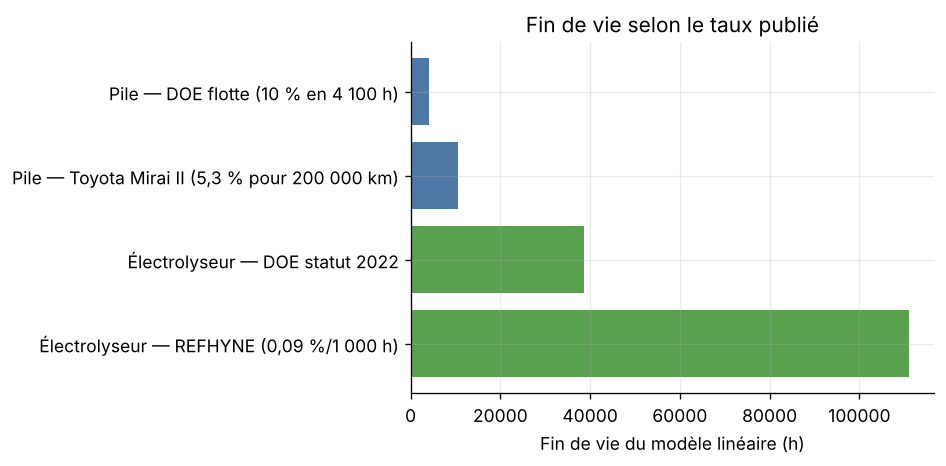

In [13]:
T_200K=200000./(DIST/DUR)   # h : 200 000 km à la vitesse moyenne du cycle (36 km/h)
TAUX={'Pile — DOE flotte (10 % en 4 100 h)':('FC',0.10*(FC_U300_0/FC_N)/4100.),
      'Pile — Toyota Mirai II (5,3 % pour 200 000 km)':('FC',0.053*(FC_U300_0/FC_N)/T_200K),
      'Électrolyseur — DOE statut 2022':('WE',4.8e-6),
      'Électrolyseur — REFHYNE (0,09 %/1 000 h)':('WE',0.0009*WE_VREF0/1000.)}
sens=[]
for nom,(sy,k) in TAUX.items():
    if sy=='FC': eol=.10*(FC_U300_0/FC_N)/k; sec=np.nan
    else: eol=.10*WE_VREF0/k; sec=(WE_E0+k*AGE_WE_MAIN*WE_W0)/WE_H20
    sens.append({'Taux':nom,'mu_uV_h':1e6*k,'EoL_h':eol,'SEC_WE_15000h':sec})
sens_simple=pd.DataFrame(sens);display(sens_simple.round(2))
fig,ax=plt.subplots(figsize=(8,4))
ax.barh(sens_simple.Taux,sens_simple.EoL_h,color=['#4E79A7','#4E79A7','#59A14F','#59A14F'])
ax.set(xlabel='Fin de vie du modèle linéaire (h)',title='Fin de vie selon le taux publié');ax.invert_yaxis()
fig.tight_layout();fig.savefig(OUT/'CMP_07_taux_litterature.png',dpi=220);plt.show()


## 15. Les trois cas retenus dans l'étude

L'étude retient trois cas, tous fondés sur des valeurs publiées :

| Cas | Pile | Électrolyseur |
|---|---|---|
| Optimiste | linéaire, objectif ultime du DOE (8 000 h jusqu'à 10 % de perte de tension) | linéaire, objectif 2026 du DOE (2,3 µV/h) |
| Central | linéaire, DOE (10 % en 4 100 h) | linéaire, DOE statut 2022 (4,8 µV/h) |
| Pessimiste | modèle par mécanismes, cellule C | modèle par mécanismes, jeu « Pessimiste » |

Pour l'électrolyseur, seul le jeu « Pessimiste » du modèle par mécanismes est utilisé : les jeux « Optimiste » et « Moyen » mêlaient l'activité de l'anode et sa capacité. La cellule suivante calcule la fin de vie et le nombre de stacks de chaque cas ; ils doivent être identiques aux valeurs de référence.


In [14]:
import math
L_FC_H,L_WE_H=200000./(DIST/DUR),90000.
cas=[]
for nom,k in [('Optimiste',0.10*(FC_U300_0/FC_N)/8000.),('Central',TAUX['Pile — DOE flotte (10 % en 4 100 h)'][1])]:
    e=.10*(FC_U300_0/FC_N)/k; cas.append({'Équipement':'Pile','Cas':nom,'mu_uV_h':1e6*k,'EoL_h':e,'Stacks':math.ceil(L_FC_H/e-1e-9)})
e=fc_eol_scenarios['Pessimiste']; cas.append({'Équipement':'Pile','Cas':'Pessimiste','mu_uV_h':float('nan'),'EoL_h':e,'Stacks':math.ceil(L_FC_H/e-1e-9)})
for nom,k in [('Optimiste',2.3e-6),('Central',TAUX['Électrolyseur — DOE statut 2022'][1])]:
    e=.10*WE_VREF0/k; cas.append({'Équipement':'Électrolyseur','Cas':nom,'mu_uV_h':1e6*k,'EoL_h':e,'Stacks':math.ceil(L_WE_H/e-1e-9)})
e=we_eol_scenarios['Pessimiste']; cas.append({'Équipement':'Électrolyseur','Cas':'Pessimiste','mu_uV_h':float('nan'),'EoL_h':e,'Stacks':math.ceil(L_WE_H/e-1e-9)})
cas_article=pd.DataFrame(cas); display(cas_article.round(1))
# Contrôle avec l'article (tableau des fins de vie) : écart toléré 1 %
ref={('Pile','Optimiste'):8000,('Pile','Central'):4100,('Pile','Pessimiste'):2895,('Électrolyseur','Optimiste'):80870,('Électrolyseur','Central'):38750,('Électrolyseur','Pessimiste'):34175}
for _,r in cas_article.iterrows():
    v=ref[(r['Équipement'],r['Cas'])]; print(r['Équipement'],r['Cas'],round(r['EoL_h']),'article :',v, 'OK' if abs(r['EoL_h']/v-1)<.01 else 'ÉCART')


,Équipement,Cas,mu_uV_h,EoL_h,Stacks
0,Pile,Optimiste,9.2,8000.0,1
1,Pile,Central,17.9,4100.0,2
2,Pile,Pessimiste,NaN,2894.5,2
3,Électrolyseur,Optimiste,2.3,80869.8,2
4,Électrolyseur,Central,4.8,38750.1,3
5,Électrolyseur,Pessimiste,NaN,34175.4,3


Pile Optimiste 8000 référence : 8000 OK
Pile Central 4100 référence : 4100 OK
Pile Pessimiste 2895 référence : 2895 OK
Électrolyseur Optimiste 80870 référence : 80870 OK
Électrolyseur Central 38750 référence : 38750 OK
Électrolyseur Pessimiste 34175 référence : 34175 OK


## 14. Synthèse, interprétation et limites

Le modèle linéaire est transparent et adapté lorsqu'un taux de dégradation global est la seule donnée disponible. Il suppose une perte indépendante du courant et ne permet pas d'expliquer quel mécanisme gouverne l'impact.

Le modèle complexe relie les impacts à des mécanismes interprétables et à des mesures publiées. Pour la PEMFC, il fait apparaître le rôle du crossover, qui peut fixer la fin de vie avant la perte de tension. Pour le PEMWE, il sépare la perte d'activité de l'anode, qui sature, de la croissance des résistances, qui dépend de la densité de courant du profil.

La différence entre les deux modèles est une **incertitude de structure**. Elle ne doit pas être confondue avec l'incertitude paramétrique étudiée par Monte-Carlo.

In [15]:
summary=pd.DataFrame([
 {'Système':'PEMFC','Modèle':'Simple linéaire','EoL_h':fc_eol_simple,'Indicateur_age_commun':'H2 kg/cycle','Valeur_age_commun':fc_s['H2']},
 *[{'Système':'PEMFC','Modèle':f'Complexe — {name}','EoL_h':fc_eol_scenarios[name],
    'Indicateur_age_commun':'H2 kg/cycle','Valeur_age_commun':fc_states_all[f'Complexe — {name}']['H2']}
   for name in ['Optimiste','Moyen','Pessimiste']],
 {'Système':'PEMWE','Modèle':'Simple linéaire','EoL_h':we_eol_simple,'Indicateur_age_commun':'SEC kWh/kg','Valeur_age_commun':float(we_s['SEC'])},
 *[{'Système':'PEMWE','Modèle':f'Complexe — {name}','EoL_h':we_eol_scenarios[name],
    'Indicateur_age_commun':'SEC kWh/kg','Valeur_age_commun':float(we_states_all[f'Complexe — {name}']['SEC'])}
   for name in ['Optimiste','Moyen','Pessimiste']]])
display(summary.round(5))
checks={'États initiaux PEMFC identiques':np.isclose(fc_state_simple(0)['H2'],fc_state(0,FC_CENTRAL)['H2']),
        'États initiaux PEMWE identiques':np.isclose(we_state_simple(0)['SEC'],we_state(0,WE_CENTRAL)['SEC']),
        'Horizon FC avant toutes les EoL':AGE_FC_MAIN<min([fc_eol_simple,*fc_eol_scenarios.values()]),
        'Horizon WE avant toutes les EoL':AGE_WE_MAIN<min([we_eol_simple,*we_eol_scenarios.values()]),
        'Résultats ACV finis':np.isfinite(acv_age_commun[['Impact_simple','Impact_complexe']]).all().all(),
        'Résultats EoL propres finis':np.isfinite(acv_own_life['Impact']).all(),
        'Matrice finie':np.isfinite(matrix_models.Impact_par_km).all()}
display(pd.DataFrame({'Contrôle':checks.keys(),'OK':checks.values()}));assert all(checks.values())

fc_cmp.to_csv(OUT/'CMP_PEMFC_trajectoires.csv',index=False,encoding='utf-8-sig')
fc_endpoints.to_csv(OUT/'CMP_PEMFC_resultats_EOL_propres.csv',index=False,encoding='utf-8-sig')
fc_common.to_csv(OUT/'CMP_PEMFC_resultats_age_commun.csv',index=False,encoding='utf-8-sig')
we_cmp.to_csv(OUT/'CMP_PEMWE_trajectoires.csv',index=False,encoding='utf-8-sig')
we_endpoints.to_csv(OUT/'CMP_PEMWE_resultats_EOL_propres.csv',index=False,encoding='utf-8-sig')
we_common.to_csv(OUT/'CMP_PEMWE_resultats_age_commun.csv',index=False,encoding='utf-8-sig')
acv_age_commun.to_csv(OUT/'CMP_ACV_age_commun_16_indicateurs.csv',index=False,encoding='utf-8-sig')
acv_own_life.to_csv(OUT/'CMP_ACV_EOL_propres_16_indicateurs.csv',index=False,encoding='utf-8-sig')
acv_fc_scenarios.to_csv(OUT/'CMP_ACV_PEMFC_scenarios_16_indicateurs.csv',index=False,encoding='utf-8-sig')
acv_we_scenarios.to_csv(OUT/'CMP_ACV_PEMWE_scenarios_16_indicateurs.csv',index=False,encoding='utf-8-sig')
eol_fc_table.to_csv(OUT/'CMP_PEMFC_EoL_modeles.csv',index=False,encoding='utf-8-sig')
acv_cum_compare.to_csv(OUT/'CMP_ACV_cumule_16_indicateurs.csv',index=False,encoding='utf-8-sig')
matrix_models.to_csv(OUT/'CMP_matrice_modeles_couplage.csv',index=False,encoding='utf-8-sig')
sens_simple.to_csv(OUT/'CMP_sensibilite_taux_lineaires.csv',index=False,encoding='utf-8-sig')
summary.to_csv(OUT/'CMP_resume_modeles.csv',index=False,encoding='utf-8-sig')
print('Notebook validé. Résultats exportés dans :',OUT.resolve())


,Système,Modèle,EoL_h,Indicateur_age_commun,Valeur_age_commun
0,PEMFC,Simple linéaire,4100.00000,H2 kg/cycle,0.20926
1,PEMFC,Complexe — Optimiste,5807.95279,H2 kg/cycle,0.20705
2,PEMFC,Complexe — Moyen,3827.89673,H2 kg/cycle,0.21314
3,PEMFC,Complexe — Pessimiste,2894.51639,H2 kg/cycle,0.22109
4,PEMWE,Simple linéaire,38750.11602,SEC kWh/kg,55.67528
5,PEMWE,Complexe — Optimiste,61311.45564,SEC kWh/kg,55.64643
6,PEMWE,Complexe — Moyen,46533.27592,SEC kWh/kg,56.29350
7,PEMWE,Complexe — Pessimiste,34175.40693,SEC kWh/kg,57.22691


,Contrôle,OK
0,États initiaux PEMFC identiques,True
1,États initiaux PEMWE identiques,True
2,Horizon FC avant toutes les EoL,True
3,Horizon WE avant toutes les EoL,True
4,Résultats ACV finis,True
5,Résultats EoL propres finis,True
6,Matrice finie,True


Notebook validé. Résultats exportés dans : ./resultats_sensibilite_these
